# FIFA 24: Player Value Prediction and Analysis Using Player Performance Metrics

**Abstract.** We predict FIFA 24 player market values from in-game attributes and test how the attributes that drive value depend on a player's role. The data is the FIFA 24 Player Stats dataset (Kaggle, `player_stats.csv`, 5,682 players × 41 columns).

The analysis covers:
* Careful data cleaning, including a value format that is easy to mis-parse.
* Exploratory data analysis and unsupervised discovery of playing roles.
* A comparison of linear, regularised, transformed, tree-ensemble, dimensionality-reduction and interaction models, all under one cross-validated protocol.
* Role-based hypothesis tests.
* What drives value: the age curve, the price of ability, SHAP explanations.
* Calibrated prediction intervals, a bargain finder and a style-twin scout.

### Contents
1. Data loading and cleaning
2. Exploratory data analysis
3. Discovering playing roles
4. Modelling and model selection
5. Hypothesis testing by role
6. What drives value?
7. Prediction intervals, bargains and scouting
8. Conclusion

In [1]:
import io
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import shap
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.cluster import KMeans
from sklearn.compose import TransformedTargetRegressor, make_column_transformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import Lasso, LassoCV, LinearRegression, Ridge, RidgeCV
from sklearn.metrics import mean_squared_error, r2_score, silhouette_score
from sklearn.model_selection import KFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (OneHotEncoder, PolynomialFeatures, PowerTransformer, SplineTransformer,
                                   StandardScaler, TargetEncoder)
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore")
pd.options.display.max_columns = 50
sns.set_theme(style="whitegrid", palette="deep")
BLUE, RED = "#2f6f8f", "#b5523b"

try:  # XGBoost needs libomp on macOS (`brew install libomp`); fall back to sklearn's equivalent
    from xgboost import XGBRegressor
    XGBRegressor(n_estimators=1).fit(np.zeros((2, 1)), [0, 1])
    make_xgb = lambda: XGBRegressor(random_state=0, n_jobs=-1)
    BOOSTER = "XGBoost"
except Exception:
    make_xgb = lambda: HistGradientBoostingRegressor(random_state=0)
    BOOSTER = "XGBoost*"  # * = sklearn HistGradientBoosting stand-in
print("Gradient booster used for the XGBoost models:", BOOSTER)

Gradient booster used for the XGBoost models: XGBoost*


---
## 1. Data loading and cleaning

### 1.1 Encoding
Most rows are UTF-8 but a few (e.g. *Kylian Mbappé*) are Latin-1. Reading the whole file as ISO-8859-1 garbles ~1,400 names (`Thomas DÃ¤hne`). Reading it as UTF-8 crashes. So we decode line by line.

In [2]:
lines = []
with open("player_stats.csv", "rb") as fh:
    for line in fh:
        try:
            lines.append(line.decode("utf-8"))
        except UnicodeDecodeError:
            lines.append(line.decode("latin-1"))
raw = pd.read_csv(io.StringIO("".join(lines)), na_values=["None"])
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 5682 entries, 0 to 5681
Data columns (total 41 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   player          5682 non-null   str    
 1   country         5682 non-null   str    
 2   height          5682 non-null   int64  
 3   weight          5682 non-null   int64  
 4   age             5682 non-null   int64  
 5   club            5682 non-null   str    
 6   ball_control    5682 non-null   int64  
 7   dribbling       5682 non-null   int64  
 8   marking         0 non-null      float64
 9   slide_tackle    5682 non-null   int64  
 10  stand_tackle    5682 non-null   int64  
 11  aggression      5682 non-null   int64  
 12  reactions       5682 non-null   int64  
 13  att_position    5682 non-null   int64  
 14  interceptions   5682 non-null   int64  
 15  vision          5682 non-null   int64  
 16  composure       5682 non-null   int64  
 17  crossing        5682 non-null   int64  
 18 

In [3]:
raw.head()

,player,country,height,weight,age,club,ball_control,dribbling,marking,slide_tackle,stand_tackle,aggression,reactions,att_position,interceptions,vision,composure,crossing,short_pass,long_pass,acceleration,stamina,strength,balance,sprint_speed,agility,jumping,heading,shot_power,finishing,long_shots,curve,fk_acc,penalties,volleys,gk_positioning,gk_diving,gk_handling,gk_kicking,gk_reflexes,value
0,Cristian Castro Devenish,Colombia,192,84,22,Atl. Nacional,55,43,NaN,68,73,72,68,30,65,30,50,33,64,49,41,55,86,40,52,43,51,64,54,30,31,32,34,41,33,10,11,6,7,9,$1.400.000
1,Silaldo Taffarel,Brazil,181,80,31,Corinthians,69,70,NaN,56,58,62,70,69,70,64,54,60,63,63,64,87,81,42,67,65,65,54,60,64,68,65,62,48,46,12,15,14,8,14,$975.00
2,Thomas Dähne,Germany,193,84,29,Holstein Kiel,25,12,NaN,13,16,27,65,17,20,49,48,14,35,18,46,38,68,41,48,36,60,17,51,14,20,20,15,26,16,64,74,65,68,74,$1.100.000
3,Michael Sollbauer,Austria,187,86,33,SK Rapid Wien,46,48,NaN,66,69,71,64,48,66,29,70,44,58,53,35,73,82,56,63,57,80,67,32,24,33,25,13,22,19,10,10,8,14,9,$650.00
4,Diego Segovia,Uruguay,191,80,23,Independiente,14,8,NaN,14,16,28,50,10,12,38,34,11,23,20,38,28,64,24,31,34,27,13,48,4,6,9,10,16,5,61,59,62,64,64,$300.00


### 1.2 Missing values
`marking` is empty for every player, so it is dropped. No other column has missing values.

In [4]:
raw.isnull().sum()[lambda s: s > 0]

marking    5682
dtype: int64

### 1.3 The value column: a 10× parsing bug
`value` is a string with `.` as the thousands separator. Only two formats exist, and **for players under €1M the last digit was truncated**: `$975.00` means €975,000.

A naive parser that strips every `.` reads `$975.00` as €97,500. That makes **every sub-million player 10× too cheap** and creates an artificial empty gap between €98k and €1M. The parser below pads the truncated group.

value
$9.9      3368
$9.9.9    2314
Name: format count, dtype: int64

Rows a naive parser would get 10x wrong: 3,368 of 5,682 (59%)


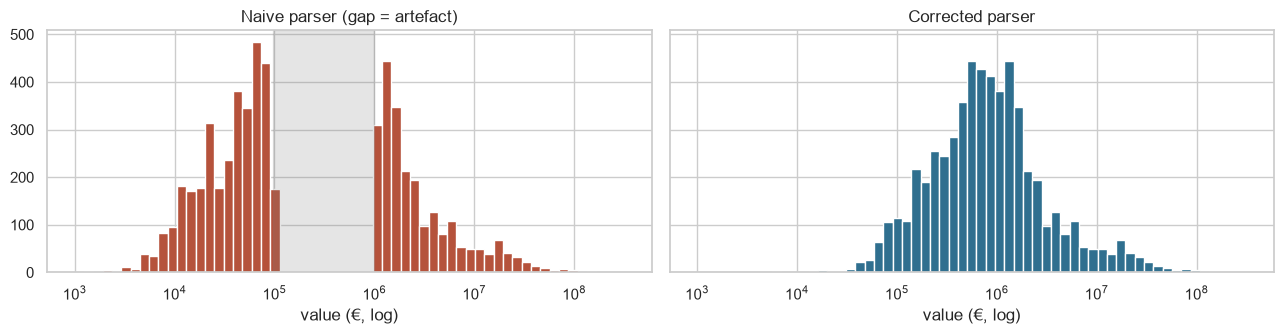

In [5]:
v = raw["value"].str.strip()
display(v.str.replace(r"\d+", "9", regex=True).value_counts().rename("format count"))


def parse_value(s):
    """'$1.400.000' -> 1_400_000 ; '$975.00 ' -> 975_000 (pad truncated thousands groups)."""
    m = re.fullmatch(r"\$?(\d{1,3}(?:\.\d{2,3})*)", str(s).strip())
    if not m:
        raise ValueError(f"unrecognised value {s!r}")
    head, *groups = m.group(1).split(".")
    return float(head + "".join(g.ljust(3, "0") for g in groups))


def naive_parser(value):  # strips every '.' (wrong for sub-million values)
    out = value.replace("$", "")
    if "." in out:
        out = float(out.replace(".", ""))
    return float(out)


assert parse_value("$1.400.000") == 1_400_000 and parse_value("$975.00 ") == 975_000
assert naive_parser("$975.00 ") == 97_500
ratio = raw["value"].map(parse_value) / raw["value"].map(naive_parser)
print(f"Rows a naive parser would get 10x wrong: {(ratio == 10).sum():,} of {len(raw):,} ({(ratio == 10).mean():.0%})")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
bins = np.logspace(3, 8.5, 60)
ax[0].hist(raw["value"].map(naive_parser), bins=bins, color=RED)
ax[0].axvspan(97_500, 1e6, color="grey", alpha=0.2)
ax[0].set(xscale="log", title="Naive parser (gap = artefact)", xlabel="value (€, log)")
ax[1].hist(raw["value"].map(parse_value), bins=bins, color=BLUE)
ax[1].set(xscale="log", title="Corrected parser", xlabel="value (€, log)")
plt.tight_layout()

### 1.4 Whitespace, duplicates, derived columns
* Club names carry trailing spaces (`"Paris SG "` vs `"Paris SG"`). These split clubs in two and hide duplicated player rows.
* `value_m` is value in € millions.
* `log_value` is the **modelling target**. Values span €4k to €153.5M (×38,000) and pricing is multiplicative, so errors are best measured in %, i.e. on the log scale.
* `is_gk`: goalkeepers have GK attributes of 50–90, outfielders 5–20, a clean split.

In [6]:
df = raw.copy()
for c in ["player", "country", "club"]:
    df[c] = df[c].astype(str).str.strip()
print("distinct clubs before / after strip:", raw.club.nunique(), "/", df.club.nunique())
df["value"] = df["value"].map(parse_value)
df = df.drop(columns=["marking"])
dup = df.duplicated(subset=["player", "club", "age", "country"])
print("duplicate rows removed:", dup.sum(), "→", list(df.loc[dup, "player"]))
df = df[~dup].reset_index(drop=True)

GK = ["gk_positioning", "gk_diving", "gk_handling", "gk_kicking", "gk_reflexes"]
df["is_gk"] = (df[GK].mean(axis=1) > 40).astype(int)
df["value_m"] = df["value"] / 1e6
df["log_value"] = np.log(df["value"])

SKILLS = list(df.loc[:, "ball_control":"gk_reflexes"].columns)
OUTF_SKILLS = [c for c in SKILLS if c not in GK]
FEATS = SKILLS + ["height", "weight", "age", "is_gk"]
print(df.shape, "| goalkeepers:", df.is_gk.sum())
df[["height", "weight", "age", "value_m", "log_value"]].describe().T.round(2)

distinct clubs before / after strip: 689 / 683
duplicate rows removed: 5 → ['Maxime Crépeau', 'Stefan Thesker', 'Cameron John', 'Kylian Mbappé', 'Sadio Mané']
(5677, 43) | goalkeepers: 632


,count,mean,std,min,25%,50%,75%,max
height,5677.0,181.67,6.83,156.00,177.00,182.00,186.00,204.00
weight,5677.0,75.28,7.00,54.00,70.00,75.00,80.00,102.00
age,5677.0,26.31,4.73,17.00,23.00,26.00,30.00,41.00
value_m,5677.0,2.47,7.17,0.00,0.35,0.78,1.60,153.50
log_value,5677.0,13.60,1.33,8.29,12.77,13.56,14.29,18.85


**Attributes** (all 0–99 except bio): `ball_control`, `dribbling`, `slide_tackle`, `stand_tackle`, `aggression`, `reactions`, `att_position` (attacking positioning), `interceptions`, `vision`, `composure`, `crossing`, `short_pass`, `long_pass`, `acceleration`, `stamina`, `strength`, `balance`, `sprint_speed`, `agility`, `jumping`, `heading`, `shot_power`, `finishing`, `long_shots`, `curve`, `fk_acc` (free-kick accuracy), `penalties`, `volleys`, and five goalkeeper attributes. Bio: `height` (cm), `weight` (kg), `age`. Identity: `player`, `country`, `club`.

---
## 2. Exploratory data analysis
### 2.1 Where do the players come from?

683 clubs, 135 countries; median players per club: 8


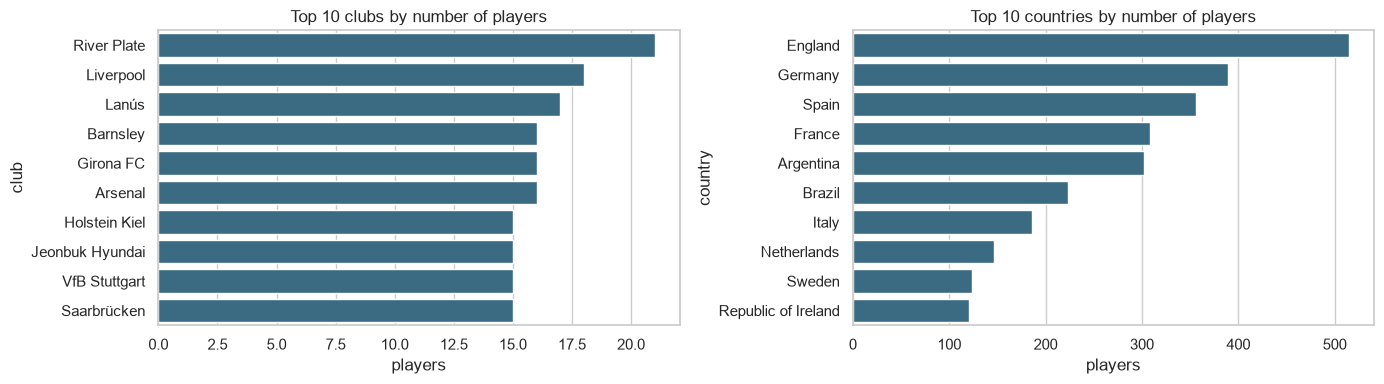

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
club = df["club"].value_counts().nlargest(10)
sns.barplot(x=club.values, y=club.index, ax=ax[0], color=BLUE)
ax[0].set(title="Top 10 clubs by number of players", xlabel="players")
country = df["country"].value_counts().nlargest(10)
sns.barplot(x=country.values, y=country.index, ax=ax[1], color=BLUE)
ax[1].set(title="Top 10 countries by number of players", xlabel="players")
plt.tight_layout()
print(f"{df.club.nunique()} clubs, {df.country.nunique()} countries; median players per club: {df.club.value_counts().median():.0f}")

The dataset is a **sample** of FIFA 24 (≤ 21 players per club, median 8), not full squads. So club counts say little about club strength.

### 2.2 Distributions of all numeric attributes
Value is shown on the log scale. On the raw scale it is a spike at zero with a long tail.

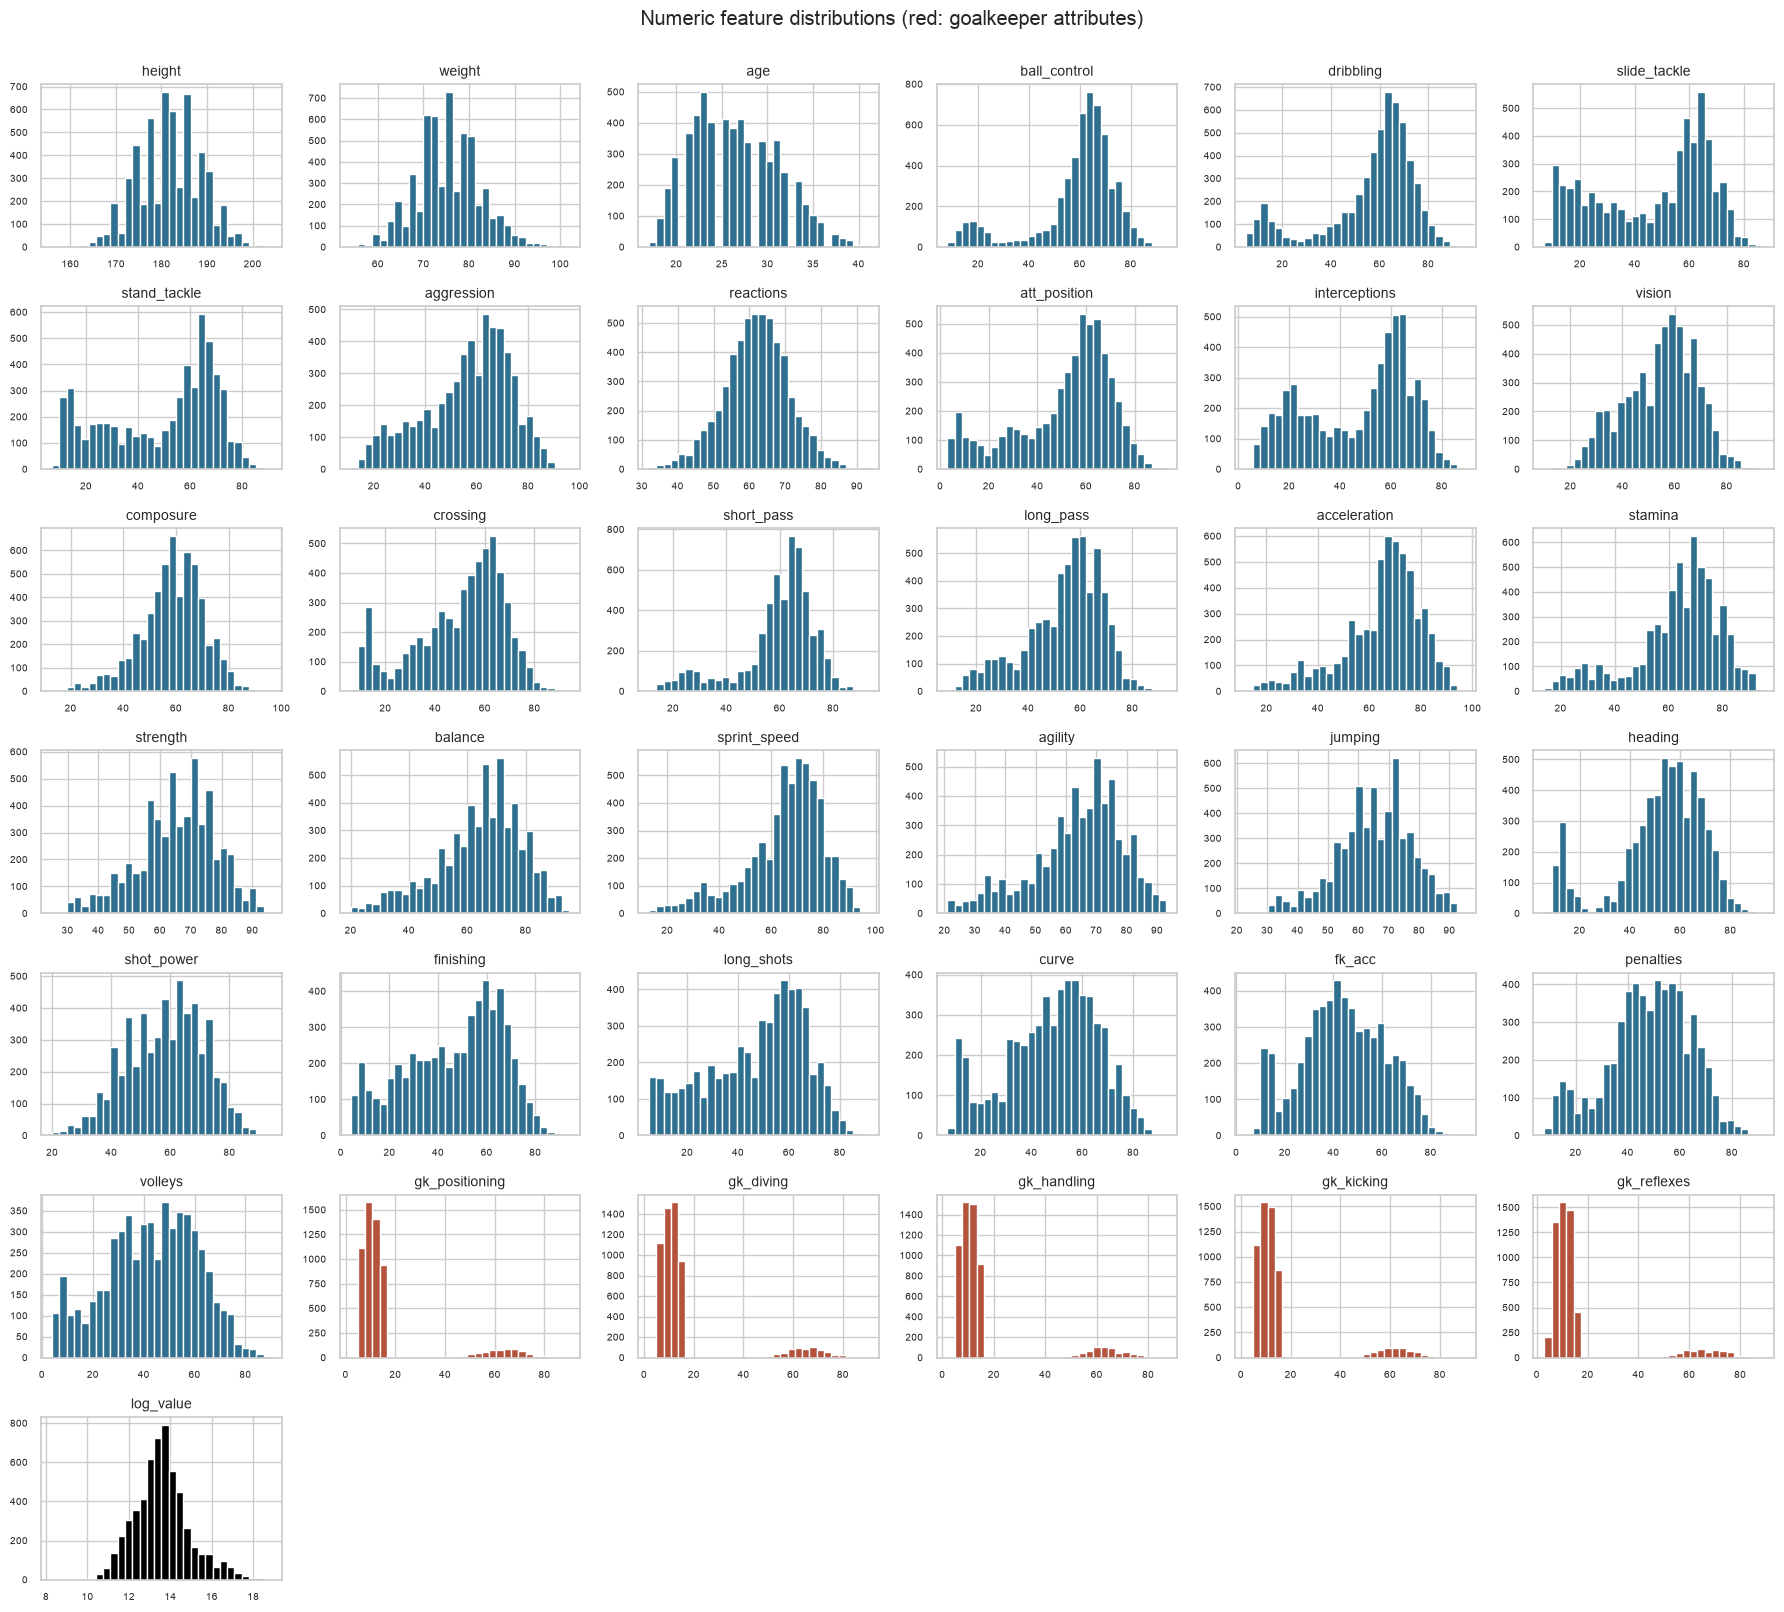

In [8]:
cols = ["height", "weight", "age"] + SKILLS + ["log_value"]
n = 6
fig, axes = plt.subplots(int(np.ceil(len(cols) / n)), n, figsize=(18, 2.3 * np.ceil(len(cols) / n)))
for ax, c in zip(axes.flat, cols):
    ax.hist(df[c], bins=30, color=RED if c.startswith("gk_") else (BLUE if c != "log_value" else "black"))
    ax.set_title(c, fontsize=10)
    ax.tick_params(labelsize=7)
for ax in axes.flat[len(cols):]:
    ax.axis("off")
plt.suptitle("Numeric feature distributions (red: goalkeeper attributes)", y=1.0)
plt.tight_layout()

* Most outfield attributes are **bimodal**. The low hump is goalkeepers, who score ~10–30 in outfield skills. The GK attributes show the mirror image.
* This GK/outfield split has to be handled explicitly (`is_gk`, roles in §3). Without it, pooled analyses mix two different populations.
* `log_value` is close to symmetric, which supports the log target.

### 2.3 Value against age and key attributes

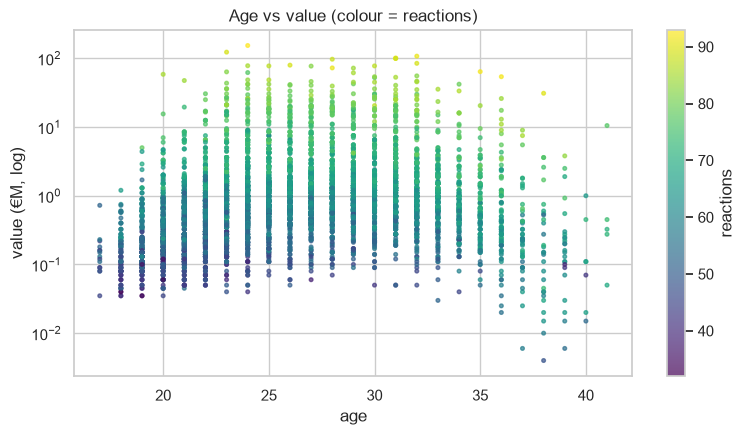

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sc = ax.scatter(df.age, df.value_m, c=df.reactions, cmap="viridis", s=7, alpha=0.7)
ax.set(yscale="log", xlabel="age", ylabel="value (€M, log)", title="Age vs value (colour = reactions)")
plt.colorbar(sc, label="reactions");

On a linear axis almost every point is crushed near zero. On a log axis the structure appears: at any given ability (colour), value rises until the mid-20s and then falls steeply after 30.

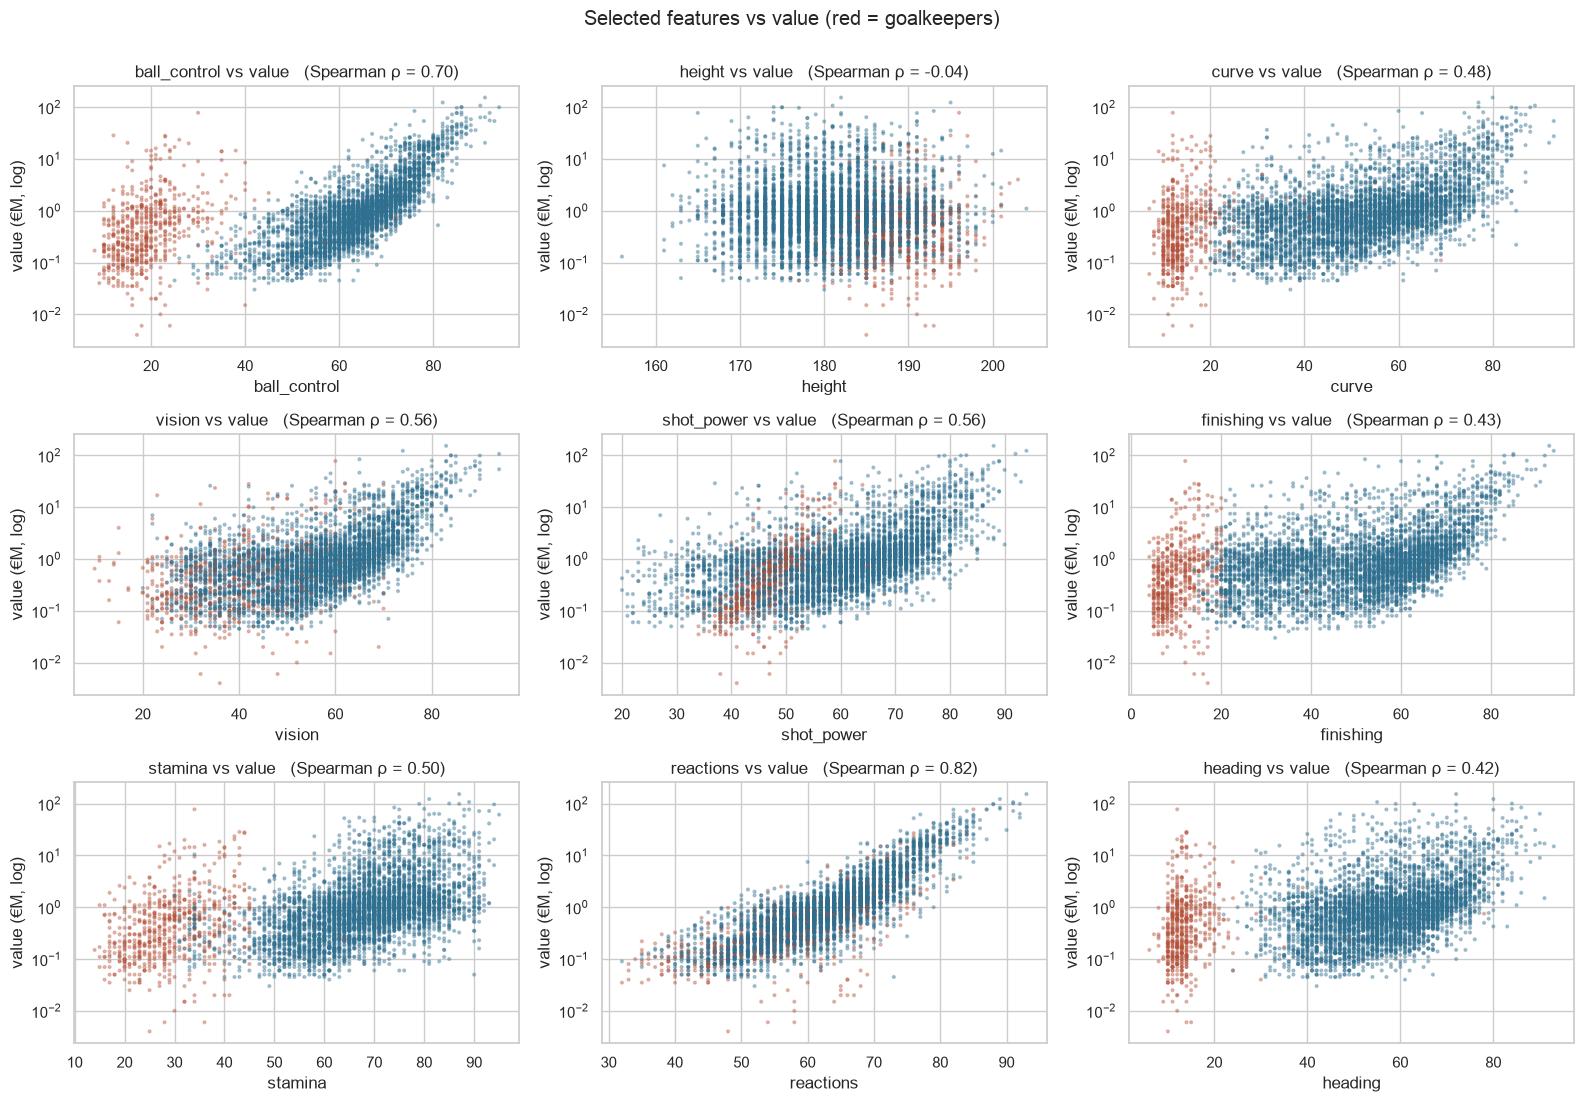

In [10]:
selected = ["ball_control", "height", "curve", "vision", "shot_power", "finishing", "stamina", "reactions", "heading"]
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, f in zip(axes.flat, selected):
    ax.scatter(df[f], df.value_m, s=4, alpha=0.35, c=np.where(df.is_gk, RED, BLUE))
    rho = stats.spearmanr(df[f], df.value_m)[0]
    ax.set(yscale="log", title=f"{f} vs value   (Spearman ρ = {rho:.2f})", xlabel=f, ylabel="value (€M, log)")
plt.suptitle("Selected features vs value (red = goalkeepers)", y=1.0)
plt.tight_layout()

* `reactions` is by far the strongest single relationship, and it is close to **linear on the log scale**, i.e. *exponential* in euros (quantified in §6).
* Skill attributes such as `finishing` and `curve` look weak in the pooled data because goalkeepers (red) are low on them yet can be expensive. Within outfielders the relationship is much clearer.
* `height` has essentially no relationship with value.

### 2.4 Correlation structure
A clustered heatmap groups attributes that move together. Each block is a set of near-redundant predictors, which explains the unstable coefficients and "insignificant" t-tests in pooled linear models.

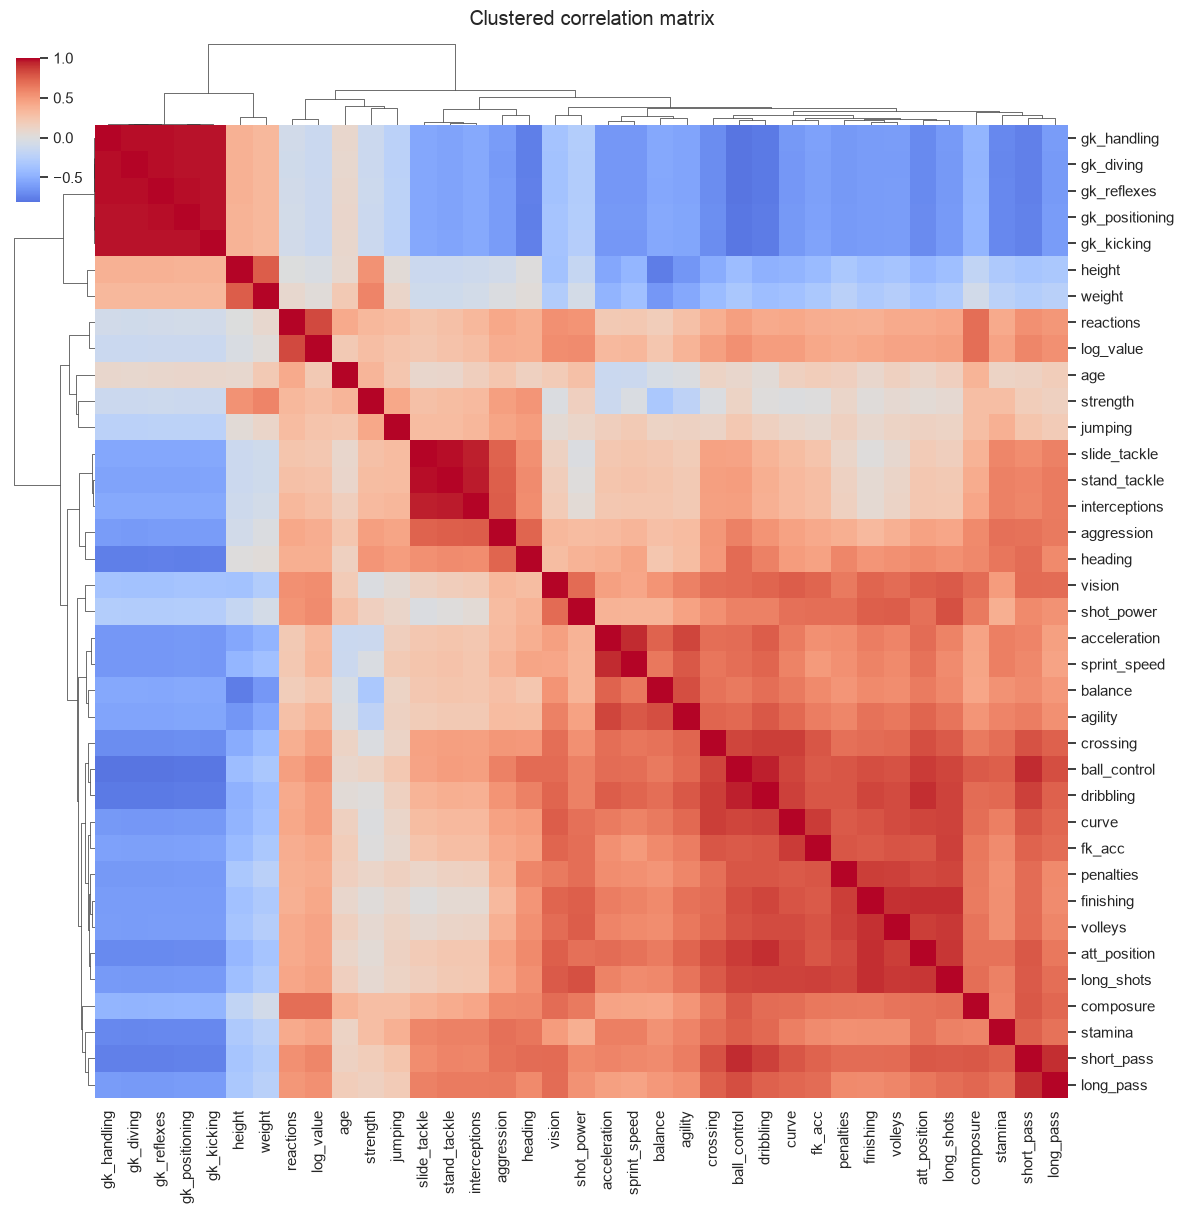

In [11]:
corr = df[["height", "weight", "age"] + SKILLS + ["log_value"]].corr()
g = sns.clustermap(corr, cmap="coolwarm", center=0, figsize=(12, 12), dendrogram_ratio=0.08, cbar_pos=(0.02, 0.85, 0.02, 0.12))
g.fig.suptitle("Clustered correlation matrix", y=1.01);

In [12]:
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(ascending=False)
print("Most collinear pairs:")
print(pairs.head(8).round(3).to_string())
print("\nCorrelation with log_value (top 8):")
print(corr["log_value"].drop("log_value").sort_values(ascending=False).head(8).round(3).to_string())

Most collinear pairs:
slide_tackle    stand_tackle    0.978
gk_diving       gk_reflexes     0.974
gk_positioning  gk_reflexes     0.973
gk_handling     gk_reflexes     0.972
gk_diving       gk_handling     0.972
gk_positioning  gk_diving       0.972
                gk_handling     0.971
gk_kicking      gk_reflexes     0.969

Correlation with log_value (top 8):
reactions       0.829
composure       0.685
short_pass      0.584
shot_power      0.566
vision          0.561
ball_control    0.542
long_pass       0.538
dribbling       0.481


---
## 3. Discovering playing roles

The dataset has **no position column**, yet the hypothesis tests in §5 are about strikers, midfielders, defenders and goalkeepers. We recover roles without labels:
1. Goalkeepers are separated by rule (`is_gk`).
2. Outfielders are clustered on their **attribute profile**: each player's attributes minus their *own* average, then standardised. Without this centring, k-means just separates good players from bad ones. With it, clusters capture *what kind* of player someone is.

In [13]:
outf = df[df.is_gk == 0]
centred = outf[OUTF_SKILLS].sub(outf[OUTF_SKILLS].mean(axis=1), axis=0)
Zrole = StandardScaler().fit_transform(centred)
sil = {k: silhouette_score(Zrole, KMeans(k, n_init=10, random_state=0).fit_predict(Zrole), sample_size=3000, random_state=0)
       for k in range(3, 10)}
print("silhouette by k:", {k: round(s, 3) for k, s in sil.items()})

silhouette by k: {3: 0.171, 4: 0.162, 5: 0.151, 6: 0.133, 7: 0.12, 8: 0.109, 9: 0.101}


Silhouette falls gently with k, because roles form a continuum (a fullback is partly a winger). We therefore choose k for interpretability: **k = 6** is the largest k where each cluster has a distinct football signature. Clusters are named by greedy matching to role signatures.

,club,role
player,,
Erling Haaland,Manchester City,Striker
Gianluigi Donnarumma,Paris SG,Goalkeeper
Virgil van Dijk,Liverpool,Centre-back
Kevin De Bruyne,Manchester City,Playmaker
Joshua Kimmich,FC Bayern München,Defensive mid
Kylian Mbappé,Paris SG,Striker
Rodri,Manchester City,Defensive mid
Mohamed Salah,Liverpool,Playmaker


,players,median_value_m,max_value_m,median_age
role,,,,
Playmaker,608,1.50,107.5,26.0
Striker,628,0.98,153.5,27.0
Defensive mid,1238,0.88,97.0,27.0
Centre-back,903,0.85,84.5,26.0
Fullback,941,0.60,27.5,25.0
Winger,727,0.60,28.0,24.0
Goalkeeper,632,0.38,78.0,27.0


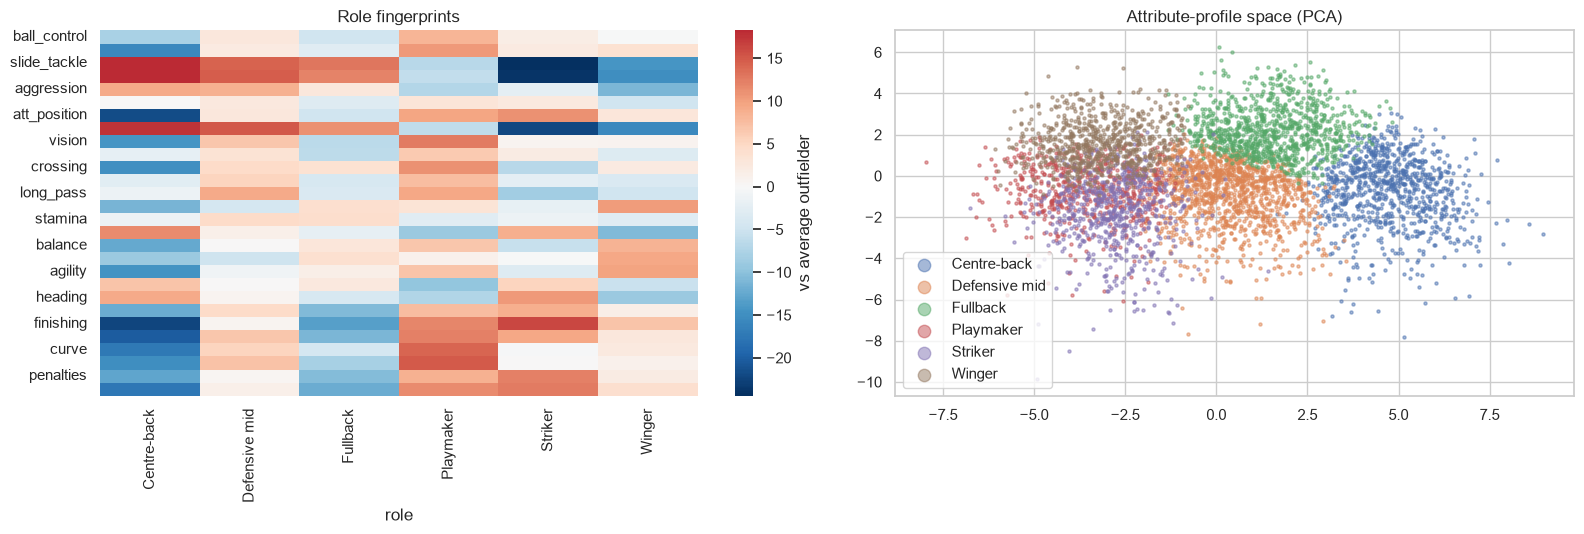

In [14]:
km = KMeans(6, n_init=20, random_state=0).fit(Zrole)
prof = centred.groupby(km.labels_).mean()
prof = prof - prof.mean()
SIGNATURES = {
    "Striker": ["finishing", "att_position", "volleys", "penalties"],
    "Winger": ["agility", "acceleration", "balance", "sprint_speed"],
    "Playmaker": ["curve", "fk_acc", "long_shots", "vision"],
    "Defensive mid": ["interceptions", "aggression", "long_pass", "stand_tackle"],
    "Centre-back": ["strength", "stand_tackle", "slide_tackle", "heading", "jumping"],
    "Fullback": ["acceleration", "slide_tackle", "crossing", "stamina"],
}
scores = sorted(((prof.loc[c, s].mean(), c, n) for c in prof.index for n, s in SIGNATURES.items()), reverse=True)
names = {}
for _, c, n in scores:
    if c not in names and n not in names.values():
        names[c] = n
df["role"] = "Goalkeeper"
df.loc[outf.index, "role"] = [names[c] for c in km.labels_]

known = ["Kylian Mbappé", "Erling Haaland", "Kevin De Bruyne", "Mohamed Salah", "Virgil van Dijk", "Rodri",
         "Joshua Kimmich", "Gianluigi Donnarumma"]
display(df[df.player.isin(known)].set_index("player")[["club", "role"]])

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
heat = df[df.is_gk == 0].groupby("role")[OUTF_SKILLS].mean()
sns.heatmap(heat.sub(heat.mean()).T, cmap="RdBu_r", center=0, ax=ax[0], cbar_kws={"label": "vs average outfielder"})
ax[0].set_title("Role fingerprints")
pc = PCA(2, random_state=0).fit_transform(Zrole)
for r in heat.index:
    m = df.loc[outf.index, "role"].values == r
    ax[1].scatter(pc[m, 0], pc[m, 1], s=5, alpha=0.5, label=r)
ax[1].legend(markerscale=4)
ax[1].set_title("Attribute-profile space (PCA)")
plt.tight_layout()

df.groupby("role").agg(players=("player", "size"), median_value_m=("value_m", "median"), max_value_m=("value_m", "max"),
                       median_age=("age", "median")).sort_values("median_value_m", ascending=False).round(2)

### 3.1 Attribute relationships, by role
Three attribute pairs (heading–height, penalties–composure, finishing–ball control), coloured by discovered role. The colour shows *why* the attributes cluster.

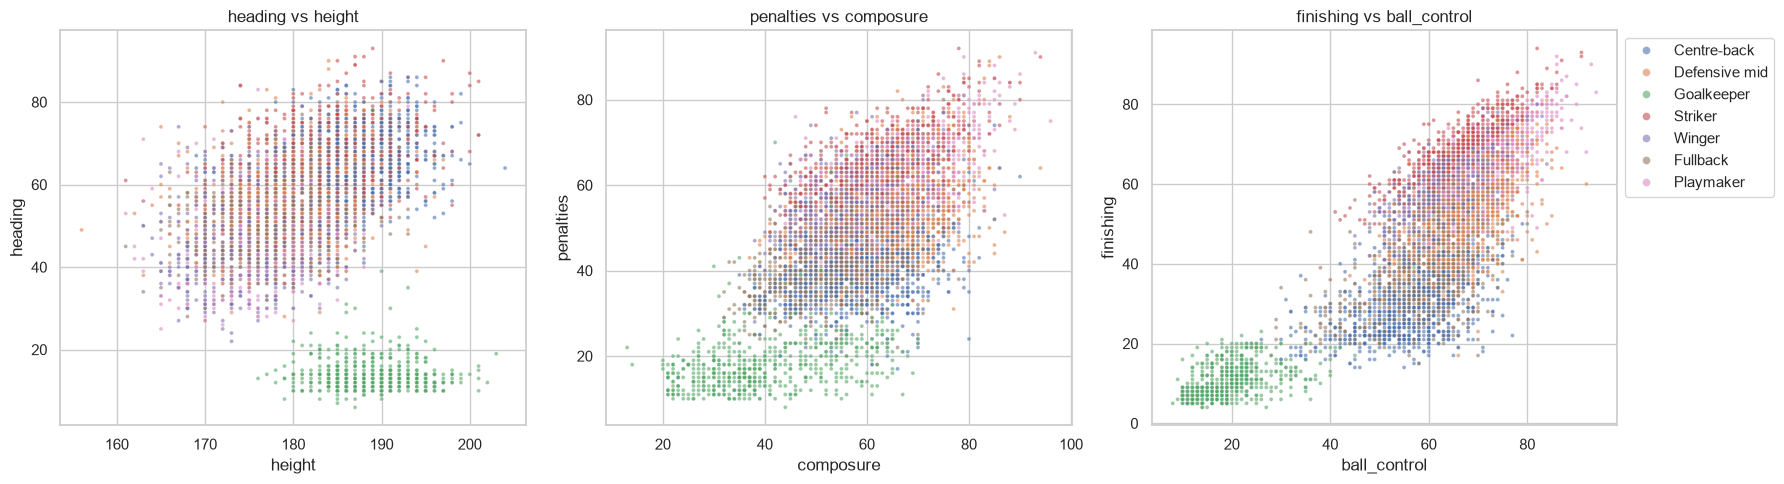

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (x, y) in zip(axes, [("height", "heading"), ("composure", "penalties"), ("ball_control", "finishing")]):
    sns.scatterplot(data=df, x=x, y=y, hue="role", s=8, alpha=0.6, ax=ax, legend=ax is axes[-1])
    ax.set_title(f"{y} vs {x}")
axes[-1].legend(markerscale=2, bbox_to_anchor=(1, 1), loc="upper left")
plt.tight_layout()

* **Heading vs height:** within outfield roles, taller players head better. Centre-backs and strikers sit highest. This is tested formally in §5.3.
* **Composure vs penalties / ball control vs finishing:** both have a lower-left goalkeeper cloud plus an outfield band ordered by role (strikers highest on finishing for a given ball control). Most of the pooled correlation between these attributes comes from mixing roles.

---
## 4. Modelling

### 4.1 Two design decisions: no outlier deletion, and cross-validation
**Should extreme values be removed?** A common recipe drops any row with |z| ≥ 4 in any column. Here is what that would delete:

In [16]:
num_cols = ["height", "weight", "age"] + SKILLS
zdf = df[num_cols + ["value_m"]]
kept = zdf[(np.abs(stats.zscore(zdf)) < 4).all(axis=1)]
dropped = df.loc[~df.index.isin(kept.index)]
print(f"z-score filter would remove {len(dropped)} rows, including "
      f"{(dropped.value_m >= 50).sum()} of the {(df.value_m >= 50).sum()} players worth ≥ €50M")
dropped.nlargest(8, "value_m")[["player", "club", "value_m"]]

z-score filter would remove 62 rows, including 25 of the 25 players worth ≥ €50M


,player,club,value_m
5226,Kylian Mbappé,Paris SG,153.5
1962,Erling Haaland,Manchester City,123.0
4846,Kevin De Bruyne,Manchester City,107.5
913,Sadio Mané,FC Bayern München,101.0
5673,Mohamed Salah,Liverpool,99.5
5674,Neymar Jr,Paris SG,99.5
5133,Joshua Kimmich,FC Bayern München,97.0
4208,Virgil van Dijk,Liverpool,84.5


It would delete the stars, the very players a valuation model most needs to handle. They are valid observations in the tail of a log-normal distribution, and on the log scale none of them are outliers. **Decision: keep every player and model log(value).**

**Is one train/test split enough to rank models?** Below, the same Random Forest is scored on 20 different random 70/30 splits:

In [17]:
r2s = pd.Series([r2_score(e, RandomForestRegressor(100, random_state=0, n_jobs=-1).fit(a, c).predict(b))
                 for a, b, c, e in (train_test_split(df[FEATS], df.log_value, test_size=0.3, random_state=s)
                                    for s in range(20))])
print(f"Random Forest test R²(log) over 20 splits: {r2s.min():.3f} – {r2s.max():.3f} (mean {r2s.mean():.3f})")

Random Forest test R²(log) over 20 splits: 0.936 – 0.945 (mean 0.940)


The score moves by about 0.01 R² with the split alone. That is as large as the gap between several models in §4.3, so one split cannot rank them reliably. **Decision: 5-fold cross-validation with out-of-fold predictions**, and every preprocessing step (scaling, selection, PCA, encoding) fitted inside the folds.

### 4.2 Residual diagnostics for the linear models (Q-Q plots)
Q-Q plots matter for the **linear** models because their p-values assume roughly normal, constant-variance errors. Fit on the corrected data with an intercept:

Box-Cox λ = -0.098 (λ ≈ 0 is the log transform)


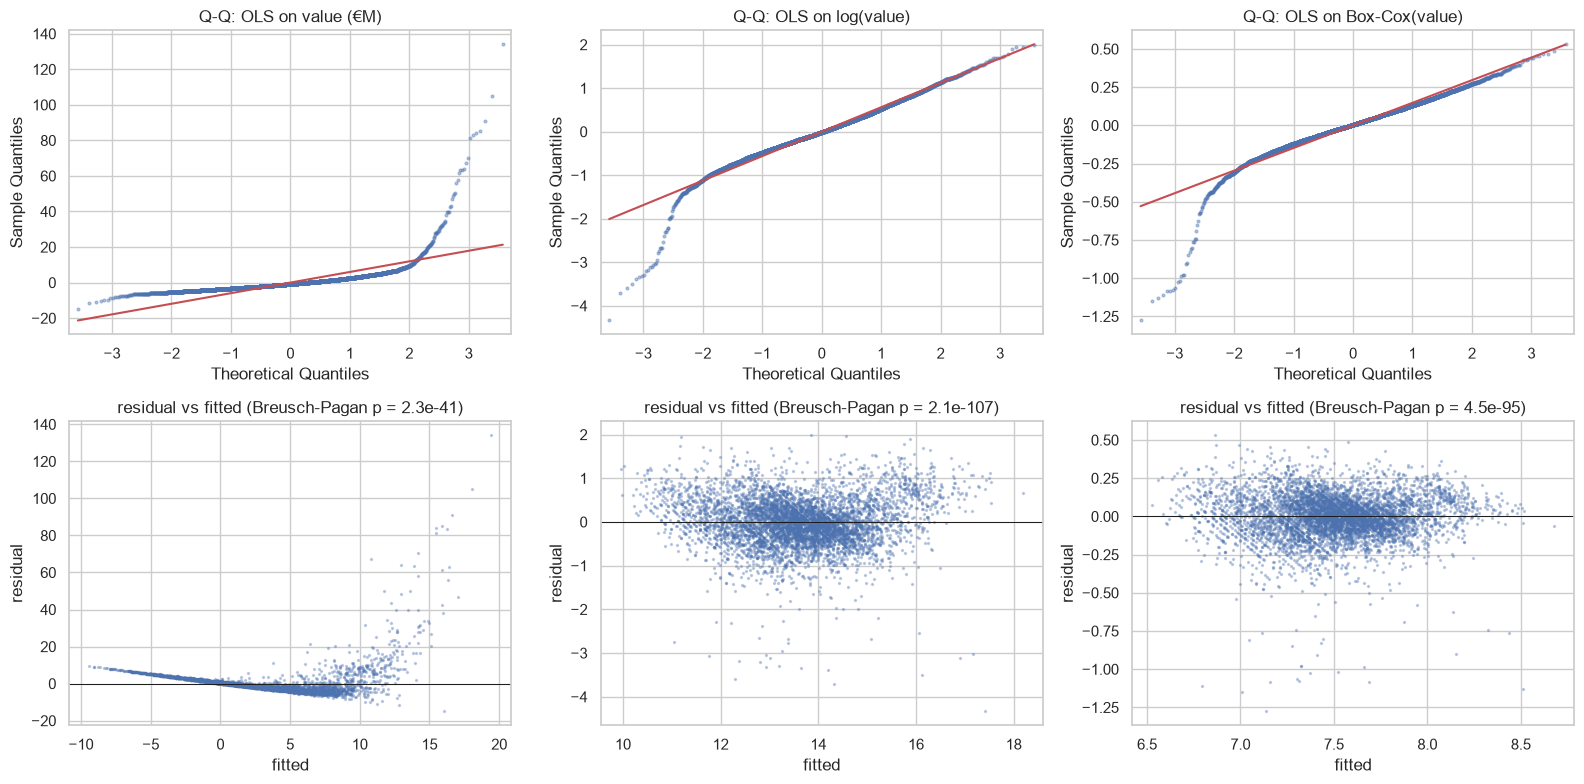

In [18]:
Xc = sm.add_constant(df[FEATS])
fits_qq = {
    "OLS on value (€M)": sm.OLS(df.value_m, Xc).fit(),
    "OLS on log(value)": sm.OLS(df.log_value, Xc).fit(),
    "OLS on Box-Cox(value)": sm.OLS(stats.boxcox(df.value)[0], Xc).fit(),
}
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for j, (name, m) in enumerate(fits_qq.items()):
    sm.qqplot(m.resid, line="s", ax=axes[0, j], markersize=2, alpha=0.4)
    axes[0, j].set_title(f"Q-Q: {name}")
    axes[1, j].scatter(m.fittedvalues, m.resid, s=2, alpha=0.3)
    axes[1, j].axhline(0, color="k", lw=0.7)
    bp = sm.stats.diagnostic.het_breuschpagan(m.resid, m.model.exog)[1]
    axes[1, j].set(title=f"residual vs fitted (Breusch-Pagan p = {bp:.1e})", xlabel="fitted", ylabel="residual")
plt.tight_layout()
print("Box-Cox λ =", round(stats.boxcox(df.value)[1], 3), "(λ ≈ 0 is the log transform)")

* On raw euros the residuals have extremely heavy tails and a fan shape, so classical OLS inference is invalid.
* The log and Box-Cox transforms (estimated λ ≈ 0, i.e. essentially the log) make residuals close to normal. Some heteroscedasticity remains, which is why §5 uses robust (HC3) standard errors.
* We use the plain log because it is simpler and coefficients read directly as "% change in value".

Q-Q plots are not shown for the tree models (Random Forest, XGBoost). Those models assume nothing about the error distribution, so a Q-Q plot says nothing about their validity. §4.4 uses error-by-value-band and predicted-vs-actual plots instead.

### 4.3 A fair comparison of every model
**Protocol, identical for every model:**
* Corrected data, all 5,677 players (no outlier deletion).
* The same 5-fold CV. All scaling, feature selection, PCA and tuning happen inside each fold. Every number is **out-of-fold**.
* Scored on the same metrics:
  * `median_ape`: median absolute % error in €. *How far off is a typical price?* This is the headline metric.
  * `within_25`: share of players priced within ±25%.
  * `rmse_log` and `r2_log`: on the log scale.
  * `r2_eur`: R² in euros. It is dominated by ~25 superstars and is shown only for comparability.

Models, by family:
* **Linear:** linear regression on €, OLS on log(value), OLS on Box-Cox(value), Ridge, Lasso, OLS with an age spline.
* **Tree ensembles:** Random Forest and XGBoost, plus XGBoost trained on euros, after Ridge feature selection, on 10 principal components, and on a hand-picked attribute subset.
* **Interactions:** Ridge with all pairwise interactions, a tuned gradient booster, and a blend of the two.

*`XGBoost*`*: if the `xgboost` package can't load (on macOS it needs `brew install libomp`), scikit-learn's HistGradientBoosting is used instead. It is the same histogram gradient-boosting algorithm with default settings. With XGBoost installed, the label drops the `*`.

In [19]:
X, y = df[FEATS], df.log_value
CV = KFold(5, shuffle=True, random_state=42)
HYP_FEATS = ["vision", "ball_control", "crossing", "curve", "dribbling", "height", "weight", "age", "slide_tackle",
             "stand_tackle", "interceptions", "short_pass", "long_pass", "stamina", "strength", "balance", "agility",
             "reactions", "long_shots", "shot_power", "finishing"]


def metrics(y_log, p_log):
    y_log, p_log = np.asarray(y_log), np.asarray(p_log)
    ape = np.abs(np.exp(p_log - y_log) - 1)
    ye, pe = np.exp(y_log), np.exp(p_log)
    return {"median_ape": np.median(ape), "within_25": np.mean(ape < 0.25),
            "rmse_log": np.sqrt(np.mean((p_log - y_log) ** 2)),
            "r2_log": 1 - np.sum((p_log - y_log) ** 2) / np.sum((y_log - y_log.mean()) ** 2),
            "r2_eur": 1 - np.sum((pe - ye) ** 2) / np.sum((ye - ye.mean()) ** 2)}


def oof(model, cols=FEATS, target="log"):
    """Out-of-fold predictions on the log scale. target='eur' trains on euros instead."""
    if target == "log":
        return cross_val_predict(model, df[cols], y, cv=CV)
    return np.log(np.clip(cross_val_predict(model, df[cols], df.value, cv=CV), 1e3, None))


age_spline = make_column_transformer((SplineTransformer(n_knots=6), ["age"]), remainder=StandardScaler())
HGB = dict(max_iter=1500, learning_rate=0.03, max_leaf_nodes=31, min_samples_leaf=10, l2_regularization=1.0, random_state=0)

P = {}  # name -> (group, oof predictions)
P["Median baseline"] = ("baseline", oof(DummyRegressor(strategy="median")))
P["Linear Regression (€ target)"] = ("linear", oof(LinearRegression(), target="eur"))
P["OLS on log(value)"] = ("linear", oof(LinearRegression()))
P["OLS on Box-Cox(value)"] = ("linear", oof(TransformedTargetRegressor(
    LinearRegression(), transformer=PowerTransformer(method="box-cox")), target="eur"))
P["Ridge (log)"] = ("linear", oof(make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 25)))))
P["Lasso (log)"] = ("linear", oof(make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=0, n_jobs=-1))))
P["Random Forest (log)"] = ("tree ensemble", oof(RandomForestRegressor(500, min_samples_leaf=2, n_jobs=-1, random_state=0)))
P[f"{BOOSTER} (log)"] = ("tree ensemble", oof(make_xgb()))
P[f"{BOOSTER} (€ target)"] = ("tree ensemble", oof(make_xgb(), target="eur"))
P[f"{BOOSTER} + Ridge feature selection"] = ("tree ensemble", oof(make_pipeline(
    StandardScaler(), SelectFromModel(Ridge(alpha=1.0)), make_xgb())))
P[f"{BOOSTER} + PCA(10)"] = ("tree ensemble", oof(make_pipeline(StandardScaler(), PCA(10, random_state=0), make_xgb())))
P[f"{BOOSTER} + hand-picked attribute subset"] = ("tree ensemble", oof(make_xgb(), cols=HYP_FEATS))
P["OLS + age spline"] = ("linear", oof(make_pipeline(age_spline, LinearRegression())))
P["Ridge, all pairwise interactions"] = ("interactions", oof(make_pipeline(
    StandardScaler(), PolynomialFeatures(2), StandardScaler(), RidgeCV(alphas=np.logspace(-1, 4, 25)))))
P["Gradient boosting, tuned"] = ("interactions", oof(HistGradientBoostingRegressor(**HGB)))
P["Blend: tuned boosting + interaction Ridge"] = ("interactions", (P["Gradient boosting, tuned"][1] + P["Ridge, all pairwise interactions"][1]) / 2)

results = pd.DataFrame({k: {"family": g, **metrics(y, p)} for k, (g, p) in P.items()}).T.sort_values("median_ape")
results.style.format({"median_ape": "{:.1%}", "within_25": "{:.1%}", "rmse_log": "{:.3f}", "r2_log": "{:.3f}",
                      "r2_eur": "{:.3f}"}).apply(
    lambda r: ["font-weight: bold" if r.name == results.index[0] else "" for _ in r], axis=1)

,family,median_ape,within_25,rmse_log,r2_log,r2_eur
Blend: tuned boosting + interaction Ridge,interactions,12.1%,81.3%,0.212,0.975,0.926
"Gradient boosting, tuned",interactions,12.6%,79.6%,0.229,0.971,0.893
XGBoost* (log),tree ensemble,13.5%,77.2%,0.245,0.966,0.864
"Ridge, all pairwise interactions",interactions,15.1%,72.4%,0.258,0.963,0.575
XGBoost* + hand-picked attribute subset,tree ensemble,16.6%,66.9%,0.310,0.946,0.862
Random Forest (log),tree ensemble,16.9%,67.9%,0.316,0.944,0.817
XGBoost* + Ridge feature selection,tree ensemble,17.4%,65.9%,0.301,0.949,0.849
XGBoost* (€ target),tree ensemble,18.5%,63.2%,0.689,0.734,0.821
XGBoost* + PCA(10),tree ensemble,21.3%,57.7%,0.360,0.927,0.806
OLS on Box-Cox(value),linear,30.8%,41.0%,0.548,0.832,0.703


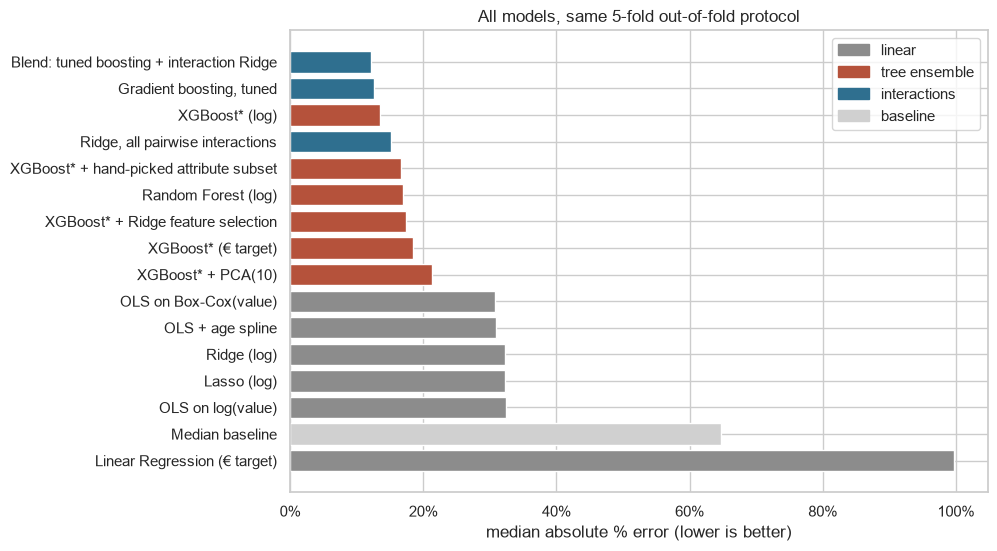

In [20]:
fig, ax = plt.subplots(figsize=(9, 6))
plot = results.iloc[::-1]
FAM = {"linear": "#8c8c8c", "tree ensemble": RED, "interactions": BLUE, "baseline": "#d0d0d0"}
colors = plot.family.map(FAM)
ax.barh(plot.index, plot.median_ape.astype(float), color=colors)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set(xlabel="median absolute % error (lower is better)", title="All models, same 5-fold out-of-fold protocol")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=f) for f, c in FAM.items()], loc="upper right");

**Reading the comparison**
* **The target scale matters most.** On euros, linear regression predicts negative values for many cheap players and is worse than the median baseline. The same model on log value is reasonable.
* **Feature selection and PCA hurt.** They are often used to deal with collinearity, but tree models don't need that, and these steps throw information away.
* **Training on euros is worse than training on log value for the same booster**, because euro-squared error lets ~25 superstars dominate the fit.
* **Interactions are most of the story.** A Ridge with all pairwise interactions comes close to boosting, which shows the non-linearity is mainly ability × age.
* **Winner: the blend.** Trees cannot predict above the highest value they saw, so boosting under-prices superstars. The interaction Ridge can extrapolate, and averaging the two fixes much of that.

### 4.4 Where does the final model fail?

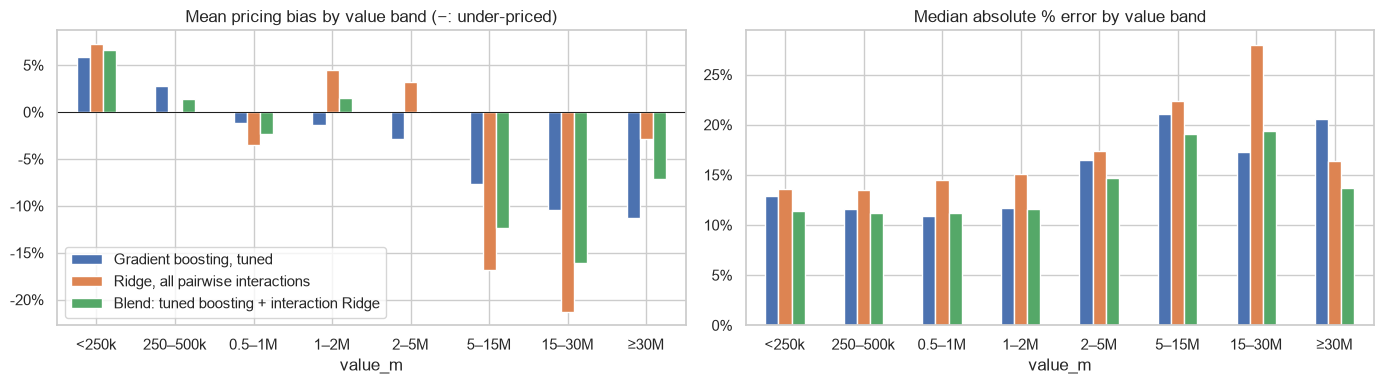

In [21]:
best = P["Blend: tuned boosting + interaction Ridge"][1]
df["pred"], df["resid"] = best, y - best
band = pd.cut(df.value_m, [0, 0.25, 0.5, 1, 2, 5, 15, 30, 200],
              labels=["<250k", "250–500k", "0.5–1M", "1–2M", "2–5M", "5–15M", "15–30M", "≥30M"])
cmp_models = ["Gradient boosting, tuned", "Ridge, all pairwise interactions", "Blend: tuned boosting + interaction Ridge"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
(np.exp(pd.DataFrame({k: pd.Series(P[k][1] - y).groupby(band).mean() for k in cmp_models})) - 1).plot.bar(
    ax=ax[0], rot=0, title="Mean pricing bias by value band (−: under-priced)")
ax[0].axhline(0, color="k", lw=0.7)
pd.DataFrame({k: pd.Series(np.abs(np.exp(P[k][1] - y) - 1)).groupby(band).median() for k in cmp_models}).plot.bar(
    ax=ax[1], rot=0, legend=False, title="Median absolute % error by value band")
for a in ax:
    a.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout()

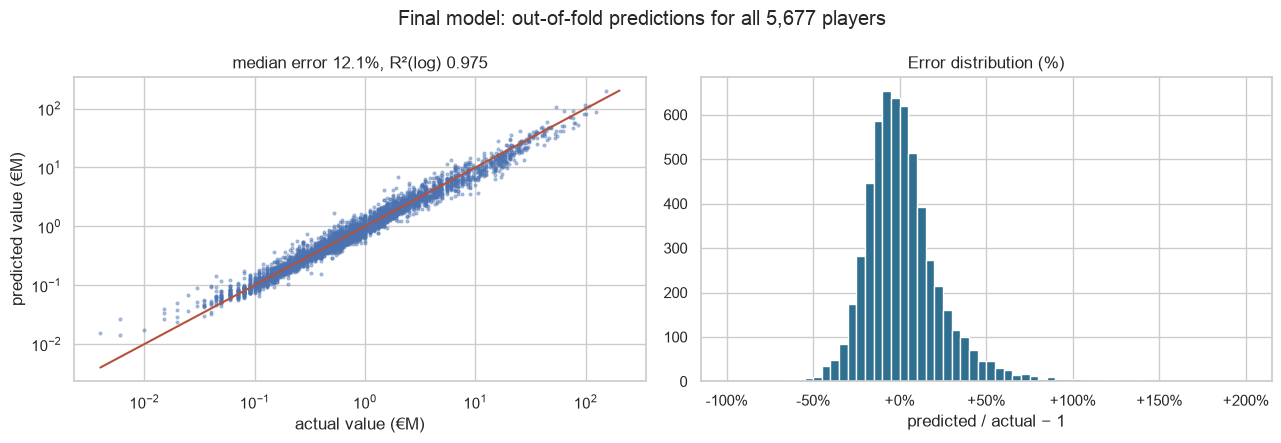

In [22]:
def plot_prediction_analysis(y_true, y_pred, title):
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
    axs[0].scatter(np.exp(y_true) / 1e6, np.exp(y_pred) / 1e6, s=4, alpha=0.4)
    lim = [np.exp(min(y_true.min(), y_pred.min())) / 1e6, np.exp(max(y_true.max(), y_pred.max())) / 1e6]
    axs[0].plot(lim, lim, c=RED)
    m = metrics(y_true, y_pred)
    axs[0].set(xscale="log", yscale="log", xlabel="actual value (€M)", ylabel="predicted value (€M)",
               title=f"median error {m['median_ape']:.1%}, R²(log) {m['r2_log']:.3f}")
    axs[1].hist(np.exp(y_pred - y_true) - 1, bins=np.linspace(-1, 2, 61), color=BLUE, edgecolor="white")
    axs[1].xaxis.set_major_formatter(lambda v, _: f"{v:+.0%}")
    axs[1].set(xlabel="predicted / actual − 1", title="Error distribution (%)")
    fig.suptitle(title)
    plt.tight_layout()


plot_prediction_analysis(y, best, "Final model: out-of-fold predictions for all 5,677 players")

* Errors are tight for the bulk of the market.
* **Known weakness:** every model under-prices the €5–30M tier by ~10–15% on average (predictions are pulled toward the mean). The blend cuts the boosting model's bias at the very top by about a third, but it is not bias-free. §7 puts honest intervals around this.

### 4.5 Does club, nationality or role add anything?
Club (683 levels) and nationality (135) are target-encoded inside each fold.

In [23]:
HGBm = lambda: HistGradientBoostingRegressor(**HGB)
enc = lambda cols, e: make_pipeline(make_column_transformer((e, cols), remainder="passthrough"), HGBm())
setups = {
    "attributes + age/height/weight (reference)": (HGBm(), FEATS),
    "+ club": (enc(["club"], TargetEncoder(target_type="continuous")), FEATS + ["club"]),
    "+ nationality": (enc(["country"], TargetEncoder(target_type="continuous")), FEATS + ["country"]),
    "+ discovered role": (enc(["role"], OneHotEncoder(sparse_output=False)), FEATS + ["role"]),
    "without age": (HGBm(), [c for c in FEATS if c != "age"]),
    "reactions + age only": (HGBm(), ["reactions", "age"]),
    "reactions only": (HGBm(), ["reactions"]),
}
abl = pd.DataFrame({k: {"n_features": len(f), **metrics(y, oof(m, cols=f))} for k, (m, f) in setups.items()}).T
abl[["n_features", "median_ape", "within_25", "r2_log"]].style.format(
    {"median_ape": "{:.1%}", "within_25": "{:.1%}", "r2_log": "{:.3f}", "n_features": "{:.0f}"})

,n_features,median_ape,within_25,r2_log
attributes + age/height/weight (reference),37,12.6%,79.6%,0.971
+ club,38,12.3%,80.1%,0.971
+ nationality,38,12.5%,79.9%,0.970
+ discovered role,38,12.4%,80.1%,0.971
without age,36,16.7%,68.5%,0.920
reactions + age only,2,37.3%,34.4%,0.768
reactions only,1,38.7%,33.1%,0.717


* **Club and nationality add nothing.** Given the attributes, playing for Real Madrid or Rochdale doesn't change the predicted price. FIFA 24 value is a formula on the player card, not a market price. This is the most important caveat for any real-world reading of this project.
* **`reactions` alone explains ~72%** of log-value variance. It is the closest proxy for the card's hidden *overall rating*. Age is the second axis: removing it costs more than any other single change.

---
## 5. Hypothesis testing by role

### 5.1 Design
**Question: do the attributes that drive value depend on a player's role?** For each role we test a fixed set of attributes that should matter for it. Design choices:

| Choice | Why |
|---|---|
| Fit each model **on that role only** (roles from §3) | A model fit on everyone mixes populations: GK attributes are noise for outfielders |
| `log(value)` target | Residuals are close to normal (§4.2); coefficient = **% value per +1 point** |
| **HC3 robust** standard errors | Some heteroscedasticity remains on the log scale |
| Control for `age + age²` | Value has a strong non-linear age curve (§6.2) |
| **Benjamini–Hochberg FDR** over all tests | ~25 tests are run |
| VIFs and **joint** tests for collinear attributes | e.g. dribbling–ball control r ≈ 0.95: individual t-tests have little power |

In [24]:
HYPOTHESES = {
    "Striker": (["Striker"], ["dribbling", "vision", "att_position", "ball_control", "reactions"]),
    "Midfielder": (["Playmaker", "Defensive mid"], ["dribbling", "vision", "crossing", "ball_control", "curve"]),
    "Goalkeeper": (["Goalkeeper"], GK),
    "Defender": (["Centre-back", "Fullback"], ["acceleration", "sprint_speed", "slide_tackle", "stand_tackle", "interceptions"]),
}


def fit_role(sub, attrs):
    return smf.ols(f"log_value ~ {' + '.join(attrs)} + age + I(age**2)", data=sub).fit(cov_type="HC3")


rows, fits, vifs = [], {}, {}
for label, (roles, attrs) in HYPOTHESES.items():
    sub = df[df.role.isin(roles)]
    m = fit_role(sub, attrs)
    fits[label] = m
    Xv = sub[attrs].assign(const=1.0).values
    vifs[label] = pd.Series([variance_inflation_factor(Xv, i) for i in range(len(attrs))], index=attrs)
    ci = m.conf_int()
    for a in attrs:
        rows.append({"model": label, "n": len(sub), "attribute": a, "% value per +1": np.expm1(m.params[a]),
                     "CI low": np.expm1(ci.loc[a, 0]), "CI high": np.expm1(ci.loc[a, 1]), "p (HC3)": m.pvalues[a]})
JOINT = [("Striker", "dribbling = ball_control = 0"), ("Midfielder", "dribbling = ball_control = 0"),
         ("Midfielder", "crossing = curve = 0"), ("Goalkeeper", "gk_positioning = gk_diving = gk_handling = gk_reflexes = 0"),
         ("Defender", "acceleration = sprint_speed = 0"), ("Defender", "slide_tackle = stand_tackle = 0")]
for mdl, h in JOINT:
    rows.append({"model": mdl, "n": int(fits[mdl].nobs), "attribute": "JOINT: " + h.replace(" = 0", "").replace(" = ", ", "),
                 "p (HC3)": float(fits[mdl].wald_test(h, scalar=True).pvalue)})
tests = pd.DataFrame(rows)
tests["p (BH)"] = multipletests(tests["p (HC3)"], method="fdr_bh")[1]
tests["significant"] = tests["p (BH)"] < 0.05

display(pd.concat(vifs, axis=1).round(1).rename_axis("VIF"))
tests.style.format({"% value per +1": "{:+.1%}", "CI low": "{:+.1%}", "CI high": "{:+.1%}", "p (HC3)": "{:.2g}",
                    "p (BH)": "{:.2g}"}, na_rep="").hide(axis="index")

,Striker,Midfielder,Goalkeeper,Defender
VIF,,,,
dribbling,5.2,4.9,NaN,NaN
vision,2.5,2.9,NaN,NaN
att_position,5.8,NaN,NaN,NaN
ball_control,8.1,5.6,NaN,NaN
reactions,4.7,NaN,NaN,NaN
crossing,NaN,2.8,NaN,NaN
curve,NaN,2.7,NaN,NaN
gk_positioning,NaN,NaN,7.9,NaN
gk_diving,NaN,NaN,6.8,NaN


model,n,attribute,% value per +1,CI low,CI high,p (HC3),p (BH),significant
Striker,628,dribbling,+2.8%,+1.9%,+3.7%,7.5e-10,1.2e-09,True
Striker,628,vision,+0.7%,+0.3%,+1.2%,0.0022,0.0026,True
Striker,628,att_position,+6.7%,+5.8%,+7.7%,1.2e-47,3.8e-47,True
Striker,628,ball_control,+4.0%,+2.9%,+5.1%,7.5e-13,1.3e-12,True
Striker,628,reactions,+3.5%,+2.8%,+4.3%,6.2e-21,1.3e-20,True
Midfielder,1846,dribbling,+0.4%,-0.5%,+1.3%,0.38,0.38,False
Midfielder,1846,vision,+2.6%,+1.9%,+3.2%,1.1e-15,2e-15,True
Midfielder,1846,crossing,+2.1%,+1.7%,+2.6%,8e-20,1.6e-19,True
Midfielder,1846,ball_control,+11.6%,+10.5%,+12.7%,9.3e-100,6.1e-99,True
Midfielder,1846,curve,-0.2%,-0.6%,+0.2%,0.29,0.3,False


### 5.2 Why the per-role design matters
The same hypotheses, fit the simple way (on *all* players, raw €, classical standard errors), against the per-role design:

In [25]:
naive = []
for label, (roles, attrs) in HYPOTHESES.items():
    m = smf.ols(f"value_m ~ {' + '.join(attrs)}", data=df).fit()
    naive += [{"model": label, "attribute": a, "p_naive": m.pvalues[a], "coef_naive": m.params[a]} for a in attrs]
naive = pd.DataFrame(naive)
naive["pooled design (all players, raw €)"] = np.where(naive.p_naive < 0.05, np.where(naive.coef_naive > 0, "raises", "LOWERS"),
                                                        "not significant")
cmp = tests[~tests.attribute.str.startswith("JOINT")].merge(naive, on=["model", "attribute"])
cmp["per-role design (log, HC3, FDR)"] = [f"raises {e:+.1%}/pt" if s and e > 0 else ("LOWERS" if s else "not significant")
                                          for e, s in zip(cmp["% value per +1"], cmp.significant)]
cmp["differs"] = np.where(cmp["pooled design (all players, raw €)"].str[:5] != cmp["per-role design (log, HC3, FDR)"].str[:5], "⚠", "")
print(f"{(cmp.differs == '⚠').sum()} of {len(cmp)} conclusions differ between the two designs")
cmp[["model", "attribute", "pooled design (all players, raw €)", "per-role design (log, HC3, FDR)", "differs"]].style.hide(axis="index")

11 of 20 conclusions differ between the two designs


model,attribute,"pooled design (all players, raw €)","per-role design (log, HC3, FDR)",differs
Striker,dribbling,not significant,raises +2.8%/pt,⚠
Striker,vision,raises,raises +0.7%/pt,
Striker,att_position,LOWERS,raises +6.7%/pt,⚠
Striker,ball_control,not significant,raises +4.0%/pt,⚠
Striker,reactions,raises,raises +3.5%/pt,
Midfielder,dribbling,LOWERS,not significant,⚠
Midfielder,vision,raises,raises +2.6%/pt,
Midfielder,crossing,not significant,raises +2.1%/pt,⚠
Midfielder,ball_control,raises,raises +11.6%/pt,
Midfielder,curve,not significant,not significant,


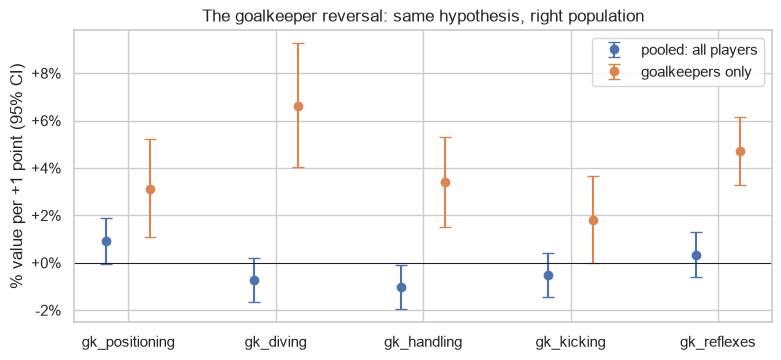

In [26]:
pooled = fit_role(df, GK)
fig, ax = plt.subplots(figsize=(9, 3.8))
xs = np.arange(len(GK))
for off, m, lbl in [(-0.15, pooled, "pooled: all players"), (0.15, fits["Goalkeeper"], "goalkeepers only")]:
    est, ci = np.expm1(m.params[GK]), np.expm1(m.conf_int().loc[GK])
    ax.errorbar(xs + off, est, yerr=[est - ci[0], ci[1] - est], fmt="o", capsize=4, label=lbl)
ax.axhline(0, color="k", lw=0.7)
ax.set_xticks(xs, GK)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:+.0%}")
ax.set(ylabel="% value per +1 point (95% CI)", title="The goalkeeper reversal: same hypothesis, right population")
ax.legend();

* **What the game pays for depends on role.** The clearest case is goalkeepers. Pooled over all players, GK attributes look irrelevant, because 89% of the sample are outfielders. Among goalkeepers, they drive the price.
* **Collinear pairs are tested jointly.** `dribbling` and `ball_control` cannot be told apart individually (high VIF), but jointly they are overwhelmingly significant.
* Coefficients are *partial* associations given the other attributes. They describe how the game prices a card, not causes in real football.

### 5.3 Does height drive heading?
Do height and weight matter for heading once jumping is known? Tested on outfield players with HC3 errors and a joint Wald test:

In [27]:
hm = smf.ols("heading ~ height + weight + jumping + strength + age", data=df[df.is_gk == 0]).fit(cov_type="HC3")
display(hm.summary().tables[1])
print("Joint test height = weight = 0: p =", f"{float(hm.wald_test('height = weight = 0', scalar=True).pvalue):.2g}")

,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,-62.8249,4.258,-14.753,0.000,-71.171,-54.479
height,0.4032,0.028,14.205,0.000,0.348,0.459
weight,0.0087,0.026,0.332,0.740,-0.043,0.060
jumping,0.2560,0.011,22.532,0.000,0.234,0.278
strength,0.3129,0.016,19.606,0.000,0.282,0.344
age,0.3310,0.027,12.367,0.000,0.279,0.383


Joint test height = weight = 0: p = 1.1e-58


**Height does matter:** each extra cm adds ~0.4 heading points, holding jumping, strength and age fixed. Weight adds nothing beyond height.

---
## 6. What drives value?
The tuned gradient booster, refit on all players, is used here as a simulator of the pricing formula.

In [28]:
model = HistGradientBoostingRegressor(**HGB).fit(X, y)

### 6.1 The exchange rate of ability

In [29]:
rows = []
for lo, hi in [(17, 21), (22, 25), (26, 29), (30, 33), (34, 45)]:
    s = df[(df.age.between(lo, hi)) & (df.is_gk == 0)]
    b = np.polyfit(s.reactions, s.log_value, 1)[0]
    rows.append({"age": f"{lo}–{hi}", "players": len(s), "% value per +1 reactions": np.expm1(b), "points to double value": np.log(2) / b})
pd.DataFrame(rows).set_index("age").style.format({"% value per +1 reactions": "{:.1%}", "points to double value": "{:.1f}"})

,players,% value per +1 reactions,points to double value
age,,,
17–21,855,11.4%,6.4
22–25,1575,13.7%,5.4
26–29,1315,14.9%,5.0
30–33,951,15.4%,4.8
34–45,349,14.8%,5.0


Each point of `reactions` multiplies value by ~1.11–1.15×, so **value doubles every ~5 points**. The step from 80 to 85 is worth far more in euros than the step from 60 to 65. A linear model on raw euros cannot represent this.

### 6.2 The age curve: identical attributes, different age

,19,23,27,30,32,34,36
reactions < 60,×0.90,×1.06,×1.00,×0.92,×0.79,×0.67,×0.33
60–70,×0.95,×1.06,×1.00,×0.92,×0.80,×0.58,×0.36
71–80,×0.99,×1.05,×1.00,×0.93,×0.82,×0.56,×0.37
> 80,×1.02,×1.06,×1.00,×0.93,×0.86,×0.64,×0.47


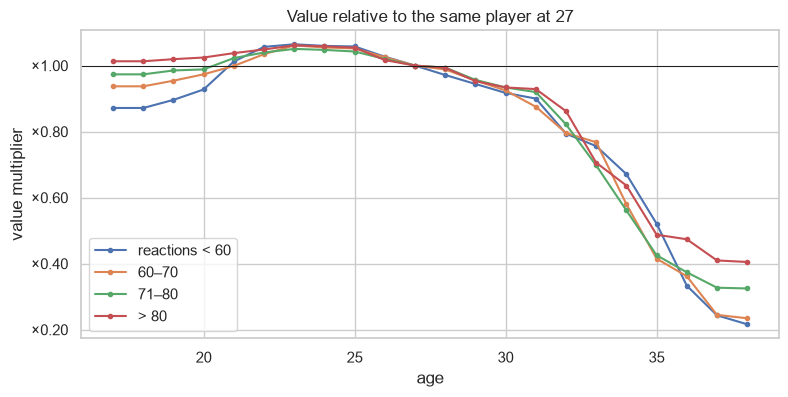

In [30]:
ages = np.arange(17, 39)
tiers = {"reactions < 60": df.reactions < 60, "60–70": df.reactions.between(60, 70),
         "71–80": df.reactions.between(71, 80), "> 80": df.reactions > 80}
curves = pd.DataFrame({name: [np.median(np.exp(model.predict(X[mask & (df.is_gk == 0)].assign(age=a))
                                               - model.predict(X[mask & (df.is_gk == 0)].assign(age=27)))) for a in ages]
                       for name, mask in tiers.items()}, index=ages)
ax = curves.plot(figsize=(9, 4), marker=".", title="Value relative to the same player at 27")
ax.axhline(1, color="k", lw=0.7)
ax.yaxis.set_major_formatter(lambda v, _: f"×{v:.2f}")
ax.set(xlabel="age", ylabel="value multiplier")
curves.loc[[19, 23, 27, 30, 32, 34, 36]].T.style.format("×{:.2f}")

Value peaks at **23–25**, is roughly flat to ~29, then drops sharply: an identical player is worth about **half as much at 34** as at 27. The youth premium for the *same* current attributes is small. The steep part of the curve is decline.

### 6.3 Price list: ability × age

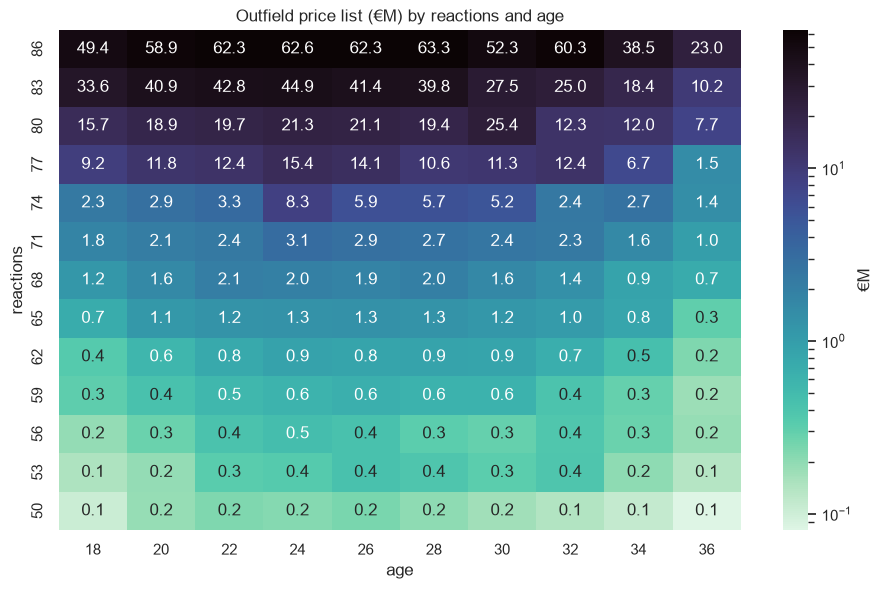

In [31]:
gm = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=0).fit(
    df.loc[df.is_gk == 0, ["reactions", "age"]], df.loc[df.is_gk == 0, "log_value"])
R, A = np.arange(50, 87, 3), np.arange(18, 37, 2)  # above ~86 the tree model plateaus (few players)
grid = pd.DataFrame([[np.exp(gm.predict(pd.DataFrame({"reactions": [r], "age": [a]}))[0]) / 1e6 for a in A] for r in R],
                    index=R, columns=A)
plt.figure(figsize=(11, 6.5))
sns.heatmap(grid.iloc[::-1], annot=True, fmt=".1f", cmap="mako_r", norm=plt.matplotlib.colors.LogNorm(), cbar_kws={"label": "€M"})
plt.title("Outfield price list (€M) by reactions and age")
plt.xlabel("age")
plt.ylabel("reactions");

### 6.4 What is each role paid for? (SHAP)
SHAP splits each prediction into per-attribute contributions on the log scale (+0.1 ≈ +10.5% value). Within each role, ranking by mean |SHAP| shows what the formula rewards for that position.

,#1,#2,#3,#4
role-specific drivers (excl. age & general quality),,,,
Centre-back,stand_tackle,interceptions,slide_tackle,short_pass
Defensive mid,short_pass,interceptions,stand_tackle,crossing
Fullback,short_pass,crossing,sprint_speed,stamina
Goalkeeper,gk_positioning,gk_handling,gk_diving,gk_reflexes
Playmaker,short_pass,dribbling,crossing,finishing
Striker,finishing,short_pass,heading,att_position
Winger,sprint_speed,short_pass,crossing,dribbling


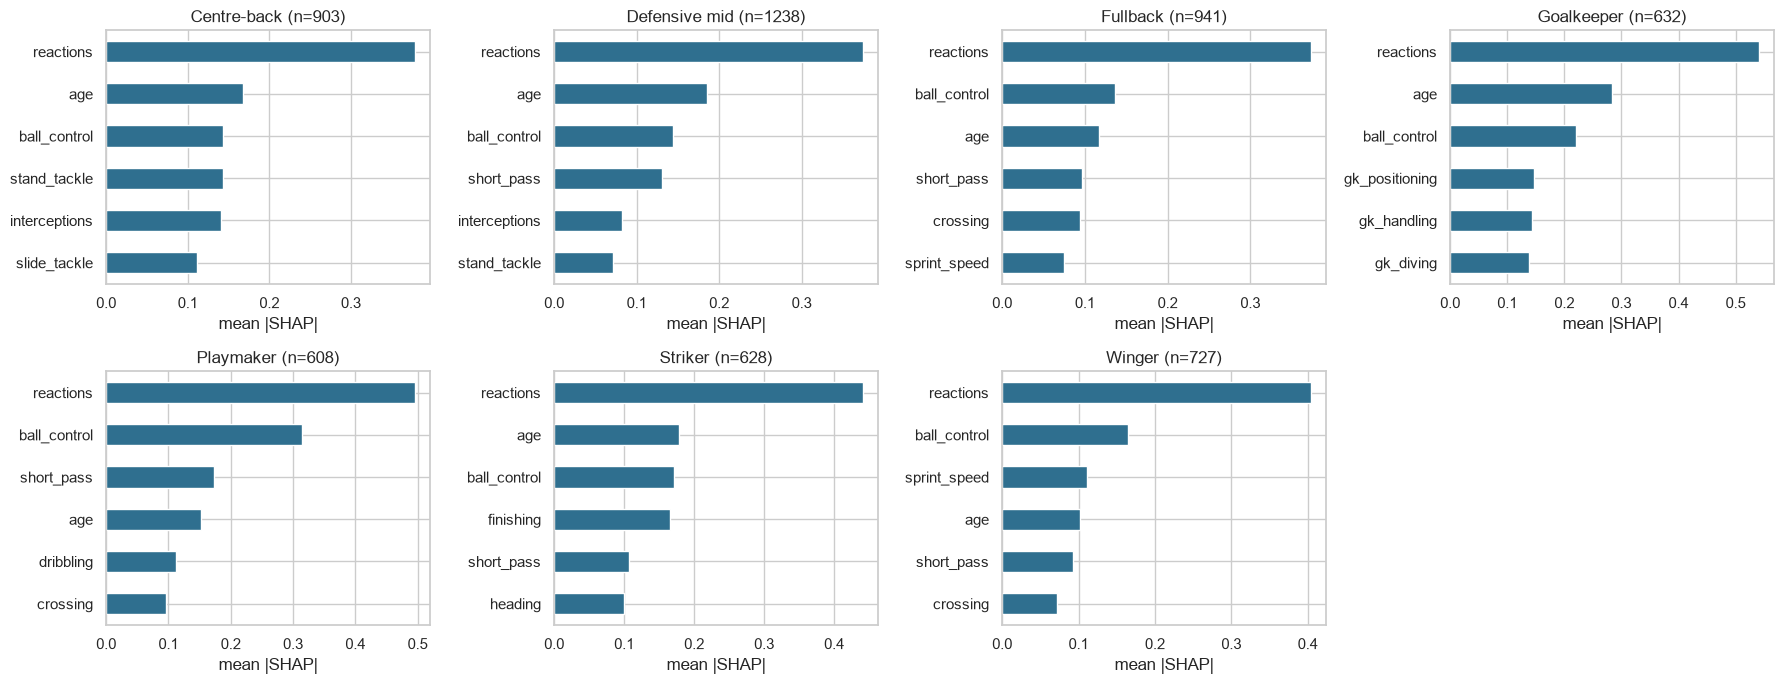

In [32]:
explainer = shap.TreeExplainer(model)
sv = pd.DataFrame(explainer.shap_values(X), columns=FEATS, index=df.index)
imp = sv.abs().groupby(df.role).mean().drop(columns=["is_gk"])
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, r in zip(axes.flat, imp.index):
    imp.loc[r].nlargest(6)[::-1].plot.barh(ax=ax, color=BLUE)
    ax.set_title(f"{r} (n={(df.role == r).sum()})")
    ax.set_xlabel("mean |SHAP|")
axes.flat[-1].axis("off")
plt.tight_layout()

generic = {"age", "reactions", "composure", "ball_control"}
pd.DataFrame({r: [f for f in imp.loc[r].sort_values(ascending=False).index if f not in generic][:4] for r in imp.index},
             index=["#1", "#2", "#3", "#4"]).T.rename_axis("role-specific drivers (excl. age & general quality)")

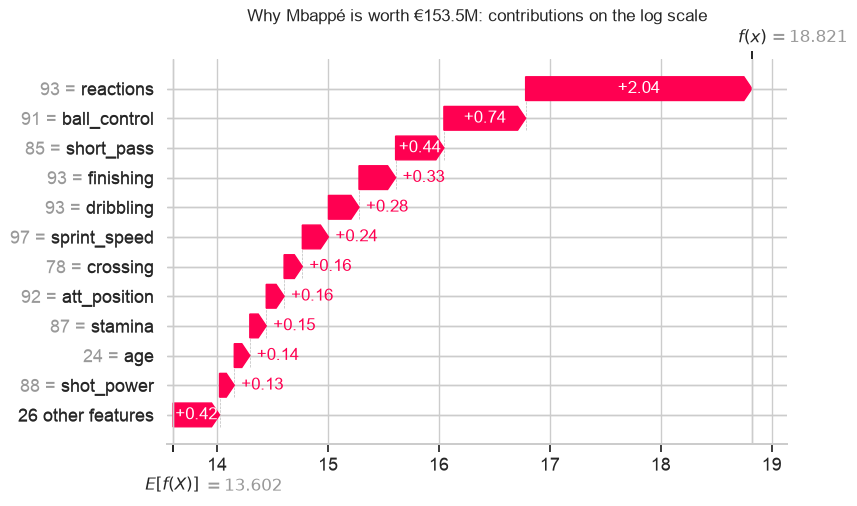

In [33]:
i = df.index[df.player == "Kylian Mbappé"][0]
wax = shap.plots.waterfall(shap.Explanation(sv.loc[i].values, float(np.ravel(explainer.expected_value)[0]), X.loc[i].values, feature_names=FEATS),
                     max_display=12, show=False)
wax.set_title(f"Why Mbappé is worth €{df.value_m[i]:.1f}M: contributions on the log scale")
wfig = wax.figure
wfig.set_size_inches(8, 5)
display(wfig)
plt.close(wfig)

### 6.5 Upgrade ROI: which +5 is worth the most?

In [34]:
def upgrade_roi(name, step=5, top=6):
    i = df.index[df.player == name][0]
    base = model.predict(X.loc[[i]])[0]
    cand = (GK + ["reactions"]) if df.is_gk[i] else OUTF_SKILLS
    gains = {}
    for c in cand:
        x = X.loc[[i]].copy()
        x[c] = min(x[c].iloc[0] + step, 99)
        gains[c] = np.exp(model.predict(x)[0] - base) - 1
    g = pd.Series(gains).nlargest(top)
    return pd.DataFrame({"current": X.loc[i, g.index].astype(int), f"value change if +{step}": g,
                         "≈ € gain": g * np.exp(base)})


for name in ["Bukayo Saka", "Rodri", "Alex Meret"]:
    r = df[df.player == name].iloc[0]
    print(f"\n{name} ({r.role}, age {r.age}, €{r.value_m}M)")
    display(upgrade_roi(name).style.format({"value change if +5": "{:+.1%}", "≈ € gain": "€{:,.0f}"}))


Bukayo Saka (Playmaker, age 21, €47.5M)


,current,value change if +5,≈ € gain
reactions,84,+35.4%,"€16,840,098"
sprint_speed,82,+14.9%,"€7,072,912"
short_pass,81,+14.5%,"€6,887,362"
finishing,81,+8.1%,"€3,867,823"
crossing,81,+7.4%,"€3,542,778"
interceptions,68,+4.7%,"€2,256,862"



Rodri (Defensive mid, age 27, €77.0M)


,current,value change if +5,≈ € gain
reactions,82,+31.4%,"€23,757,027"
heading,80,+7.9%,"€6,008,751"
strength,84,+5.2%,"€3,906,214"
ball_control,85,+2.7%,"€2,009,724"
crossing,63,+1.8%,"€1,342,526"
fk_acc,61,+1.0%,"€762,338"



Alex Meret (Goalkeeper, age 26, €17.0M)


,current,value change if +5,≈ € gain
reactions,74,+17.1%,"€2,890,717"
gk_kicking,70,+7.9%,"€1,332,891"
gk_positioning,80,+4.6%,"€772,402"
gk_handling,76,+0.1%,"€23,402"
gk_diving,80,+0.0%,€0
gk_reflexes,84,+0.0%,€0


The best upgrade differs by player and role. **Limitation:** for players already at the top of an attribute's range, tree models predict ~0% gain, because they cannot extrapolate beyond the best players they have seen.

---
## 7. Prediction intervals, bargains and scouting
### 7.1 Conformal price ranges that are actually calibrated
Every prediction in §4 is out-of-fold, so its absolute log-error is an honest sample of the model's error on unseen players. A conformal interval uses the 80th percentile *q* of those errors: **[price ÷ e^q, price × e^q]**. To check it, we calibrate *q* on 4 folds and measure coverage on the 5th. *Mondrian* conformal estimates a separate *q* per age band.

In [35]:
df["age_band"] = pd.cut(df.age, [0, 21, 25, 29, 32, 35, 50], labels=["≤21", "22–25", "26–29", "30–32", "33–35", "36+"])


def coverage(groups=None, alpha=0.2):
    cov, width = np.zeros(len(df), bool), np.zeros(len(df))
    for cal, te in KFold(5, shuffle=True, random_state=7).split(df):
        r = df.resid.abs().iloc[cal]
        if groups is None:
            q = np.full(len(te), np.quantile(r, 1 - alpha))
        else:
            q = df[groups].iloc[te].map(r.groupby(df[groups].iloc[cal], observed=True).quantile(1 - alpha)).astype(float).values
        cov[te], width[te] = df.resid.abs().iloc[te].values <= q, np.exp(q)
    out = pd.DataFrame({"coverage": cov, "× factor": width}).groupby(df.age_band, observed=True).mean()
    out.loc["ALL"] = [cov.mean(), np.median(width)]
    return out


cov = pd.concat({"one global q": coverage(), "Mondrian (q per age band)": coverage("age_band")}, axis=1)
cov.style.format({c: ("{:.0%}" if c[1] == "coverage" else "×{:.2f}") for c in cov.columns})

A single global *q* gives 80% coverage overall but only ~51% for players aged 36+. Per-age calibration gives ~80% in every band. Prime-age prices get a range of about ÷1.25 to ×1.25, and veterans an honestly wider ÷1.7 to ×1.7.

In [36]:
q = df.groupby("age_band", observed=True).resid.apply(lambda r: np.quantile(np.abs(r), 0.8))
df["q"] = df.age_band.map(q).astype(float)
df["fair_m"], df["lo_m"], df["hi_m"] = np.exp(df.pred) / 1e6, np.exp(df.pred - df.q) / 1e6, np.exp(df.pred + df.q) / 1e6
df["price_vs_fair"] = df.value_m / df.fair_m
SHOW = ["player", "club", "age", "role", "value_m", "fair_m", "lo_m", "hi_m"]
money = {c: "€{:.1f}M" for c in ["value_m", "fair_m", "lo_m", "hi_m"]}
df[df.player.isin(["Kylian Mbappé", "Erling Haaland", "Kevin De Bruyne", "Rodri", "Bukayo Saka", "Virgil van Dijk"])][SHOW] \
    .style.format(money).hide(axis="index")

player,club,age,role,value_m,fair_m,lo_m,hi_m
Bukayo Saka,Arsenal,21,Playmaker,€47.5M,€48.1M,€38.5M,€60.1M
Erling Haaland,Manchester City,23,Striker,€123.0M,€87.2M,€69.8M,€108.9M
Virgil van Dijk,Liverpool,32,Centre-back,€84.5M,€52.4M,€40.5M,€67.8M
Kevin De Bruyne,Manchester City,32,Playmaker,€107.5M,€110.9M,€85.7M,€143.5M
Kylian Mbappé,Paris SG,24,Striker,€153.5M,€202.7M,€162.3M,€253.2M
Rodri,Manchester City,27,Defensive mid,€77.0M,€46.3M,€36.5M,€58.6M


### 7.2 Bargain finder
Players whose actual price is **below the lower edge** of their 80% range. About 10% would fall there by chance, so we rank by distance and keep players aged ≤ 26 with reactions ≥ 70. In FIFA terms, these cards are priced below what their visible attributes imply, which makes them the best value-for-attributes signings in Career Mode.

In [37]:
print(f"{(df.value_m < df.lo_m).mean():.1%} of players below their range (≈10% expected)")
df[(df.value_m < df.lo_m) & (df.age <= 26) & (df.reactions >= 70)].sort_values("price_vs_fair")[SHOW + ["reactions", "price_vs_fair"]] \
    .head(12).style.format(money | {"price_vs_fair": "{:.0%} of fair"}).hide(axis="index")

10.5% of players below their range (≈10% expected)


player,club,age,role,value_m,fair_m,lo_m,hi_m,reactions,price_vs_fair
Dennis Geiger,TSG Hoffenheim,25,Defensive mid,€6.0M,€13.3M,€10.6M,€16.6M,79,45% of fair
Danylo Ignatenko,Bordeaux,26,Defensive mid,€1.8M,€3.4M,€2.7M,€4.3M,72,53% of fair
Jules Van Cleemput,Sp. Charleroi,26,Fullback,€1.5M,€2.8M,€2.2M,€3.5M,71,54% of fair
Valentín Gómez,Vélez Sarsfield,20,Centre-back,€1.5M,€2.8M,€2.2M,€3.5M,70,54% of fair
Carlos Augusto,Monza,24,Defensive mid,€3.5M,€6.3M,€5.1M,€7.9M,72,55% of fair
Tomás Belmonte,Lanús,25,Defensive mid,€2.7M,€4.7M,€3.8M,€5.9M,71,57% of fair
Francisco Vidangosa,Ind. Petrolero,23,Goalkeeper,€0.8M,€1.3M,€1.0M,€1.6M,75,58% of fair
Dani de Wit,AZ,25,Defensive mid,€6.5M,€11.2M,€9.0M,€14.0M,79,58% of fair
David Tavares,FC Famalicão,24,Defensive mid,€0.8M,€1.4M,€1.1M,€1.8M,70,59% of fair
António Silva,SL Benfica,19,Centre-back,€5.0M,€8.3M,€6.7M,€10.4M,78,60% of fair


### 7.3 Style-twin scout: plays like X, costs a fraction
Style similarity is the cosine similarity of centred attribute profiles (the representation from §3). Candidates must be within 10 reactions points of the target.

In [38]:
Zs = StandardScaler().fit_transform(df[OUTF_SKILLS].sub(df[OUTF_SKILLS].mean(axis=1), axis=0))
Zs /= np.linalg.norm(Zs, axis=1, keepdims=True)


def style_twins(name, n=6, max_gap=10):
    i = df.index[df.player == name][0]
    c = df.assign(style_similarity=Zs @ Zs[i])
    c = c[(c.index != i) & (c.is_gk == df.is_gk[i]) & (c.reactions >= df.reactions[i] - max_gap)]
    out = c.nlargest(n, "style_similarity")[["player", "club", "age", "reactions", "value_m", "style_similarity"]]
    out["cost vs target"] = out.value_m / df.value_m[i]
    print(f"\n{name}: {df.club[i]}, age {df.age[i]}, reactions {df.reactions[i]}, €{df.value_m[i]}M")
    return out.style.format({"value_m": "€{:.1f}M", "style_similarity": "{:.2f}", "cost vs target": "{:.0%}"}).hide(axis="index")


for star in ["Erling Haaland", "Kevin De Bruyne", "Virgil van Dijk"]:
    display(style_twins(star))


Erling Haaland: Manchester City, age 23, reactions 89, €123.0M


player,club,age,reactions,value_m,style_similarity,cost vs target
Moussa Dembélé,OL,27,80,€20.0M,0.84,16%
Aleksandar Mitrović,Fulham,28,79,€19.0M,0.84,15%
Simon Terodde,FC Schalke 04,35,79,€2.7M,0.80,2%
Tammy Abraham,Roma,25,84,€35.5M,0.80,29%
Callum Wilson,Newcastle Utd,31,81,€20.5M,0.79,17%
Valentin Castellanos,Girona FC,24,79,€12.5M,0.76,10%



Kevin De Bruyne: Manchester City, age 32, reactions 91, €107.5M


player,club,age,reactions,value_m,style_similarity,cost vs target
Mason Mount,Chelsea,24,85,€42.0M,0.94,39%
Jonas Hofmann,M'gladbach,31,83,€25.5M,0.91,24%
Bruno Fernandes,Manchester Utd,28,91,€72.5M,0.90,67%
Marco Reus,Borussia Dortmund,34,86,€33.5M,0.87,31%
Emil Forsberg,RB Leipzig,31,83,€20.5M,0.86,19%
João Mário,SL Benfica,30,81,€25.5M,0.86,24%



Virgil van Dijk: Liverpool, age 32, reactions 89, €84.5M


player,club,age,reactions,value_m,style_similarity,cost vs target
Raphaël Varane,Manchester Utd,30,85,€45.0M,0.83,53%
Rafael Tolói,Bergamo Calcio,32,83,€17.5M,0.82,21%
Nayef Aguerd,West Ham,27,80,€20.0M,0.82,24%
Kalidou Koulibaly,Chelsea,32,83,€46.5M,0.82,55%
Leonardo Bonucci,Juventus,36,80,€8.0M,0.79,9%
Gabriel,Arsenal,25,81,€30.5M,0.77,36%


---
## 8. Conclusion

**Prediction.** The best model blends a tuned gradient booster with an interaction Ridge. Out-of-fold on all 5,677 players:
* median absolute error **12.1%**
* **81%** of players priced within ±25%
* R² **0.975** on log value

Conformal 80% price ranges are calibrated within every age band.

**Modelling lessons.**
* The log target and correct value parsing matter more than the choice of algorithm.
* Feature selection and PCA reduce accuracy.
* Pairwise interactions (mostly ability × age) explain most of the non-linearity.

**What sets a FIFA 24 player's value**
1. **The card, not the club.** Club and nationality add no information once the attributes are known.
2. **Ability, exponentially.** Value doubles every ~5 points of `reactions`, the best proxy for the hidden overall rating.
3. **Age, as a cliff.** Value peaks at 23–25 and halves between 27 and 34 for identical attributes.
4. **Role-specific skills.** Goalkeepers are priced on GK attributes, defenders on tackling and interceptions, attackers on finishing and positioning. These effects only show up when roles are separated.

**Limitations.**
* The model explains FIFA 24's pricing formula, not real transfer fees.
* The €5–30M tier is under-priced by ~10–15% on average.
* Tree-based what-if analysis is unreliable at the very top of each attribute's range.
* Roles are inferred, not observed.

**References.**
1. Kaggle, *FIFA 24 Player Stats Dataset*: https://www.kaggle.com/datasets/rehandl23/fifa-24-player-stats-dataset
2. Lundberg & Lee (2017), *A Unified Approach to Interpreting Model Predictions* (SHAP).
3. Angelopoulos & Bates (2021), *A Gentle Introduction to Conformal Prediction*.
4. Benjamini & Hochberg (1995), *Controlling the False Discovery Rate*.